In [1]:

import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

# Number of manufacturing records
n = 500

# Generate manufacturing parameters
temperature = np.random.normal(220, 8, n)
pressure = np.random.normal(85, 10, n)
cycle_time = np.random.normal(42, 5, n)
cooling_time = np.random.normal(18, 3, n)
moisture = np.clip(np.random.normal(0.8, 0.25, n), 0.1, 1.8)
operator_experience = np.random.uniform(0.5, 15, n)

# Generate product quality measurements
part_weight = (
    52 + 0.03 * (pressure - 85)
    + np.random.normal(0, 1, n)
)

dimensional_deviation = np.abs(
    np.random.normal(
        0.02
        + 0.0008 * np.abs(temperature - 220)
        + 0.0005 * np.abs(pressure - 85)
        + 0.01 * moisture,
        0.025,
        n
    )
)

surface_roughness = np.clip(
    1.6
    + 0.025 * np.abs(temperature - 220)
    + 0.015 * moisture
    + np.random.normal(0, 0.15, n),
    0.5,
    None
)

# Calculate probability of manufacturing defects
defect_score = (
    -3
    + 0.08 * np.abs(temperature - 220)
    + 0.05 * np.abs(pressure - 85)
    + 1.2 * moisture
    + 0.7 * (dimensional_deviation > 0.08)
)

defect_probability = 1 / (1 + np.exp(-defect_score))

defect = np.where(
    np.random.random(n) < defect_probability,
    "Yes",
    "No"
)

# Create the manufacturing dataset
df = pd.DataFrame({
    "Machine_Temperature_C": temperature,
    "Injection_Pressure_bar": pressure,
    "Cycle_Time_sec": cycle_time,
    "Cooling_Time_sec": cooling_time,
    "Material_Moisture_pct": moisture,
    "Operator_Experience_years": operator_experience,
    "Part_Weight_g": part_weight,
    "Dimensional_Deviation_mm": dimensional_deviation,
    "Surface_Roughness_um": surface_roughness,
    "Defect": defect
})

# Display first five records
df.head()


,Machine_Temperature_C,Injection_Pressure_bar,Cycle_Time_sec,Cooling_Time_sec,Material_Moisture_pct,Operator_Experience_years,Part_Weight_g,Dimensional_Deviation_mm,Surface_Roughness_um,Defect
0,223.973713,94.261775,48.996777,20.335083,0.631205,12.304822,51.827840,0.028560,1.796697,No
1,218.893886,104.094166,46.623168,16.346443,0.763870,10.434447,53.829974,0.089242,1.528595,No
2,225.181508,71.014324,42.298152,15.545403,0.601895,2.101262,51.045095,0.020284,1.526276,No
3,232.184239,90.629692,38.765316,17.989877,0.723010,4.693218,52.527344,0.029715,1.948231,Yes
4,218.126773,78.493574,45.491117,17.489446,0.326596,4.992200,51.073851,0.077807,1.803150,No


In [2]:

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nDefect Distribution:")
print(df["Defect"].value_counts())


Dataset Shape: (500, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Machine_Temperature_C      500 non-null    float64
 1   Injection_Pressure_bar     500 non-null    float64
 2   Cycle_Time_sec             500 non-null    float64
 3   Cooling_Time_sec           500 non-null    float64
 4   Material_Moisture_pct      500 non-null    float64
 5   Operator_Experience_years  500 non-null    float64
 6   Part_Weight_g              500 non-null    float64
 7   Dimensional_Deviation_mm   500 non-null    float64
 8   Surface_Roughness_um       500 non-null    float64
 9   Defect                     500 non-null    object 
dtypes: float64(9), object(1)
memory usage: 39.2+ KB

Statistical Summary:


,Machine_Temperature_C,Injection_Pressure_bar,Cycle_Time_sec,Cooling_Time_sec,Material_Moisture_pct,Operator_Experience_years,Part_Weight_g,Dimensional_Deviation_mm,Surface_Roughness_um
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,220.054704,85.318261,42.542423,18.099564,0.797231,7.621013,52.005635,0.037629,1.757417
std,7.850026,9.779972,5.051232,2.952198,0.239559,4.120450,1.056730,0.023123,0.182746
min,194.069861,58.031134,27.518723,9.178834,0.100000,0.509474,48.835796,0.000089,1.201537
25%,214.397541,79.047083,38.987852,16.164192,0.634816,3.869569,51.201783,0.018802,1.638762
50%,220.102377,85.285316,42.599029,17.973260,0.799212,7.597873,52.042376,0.035749,1.752448
75%,225.094266,91.512423,45.773692,20.099308,0.967294,11.284170,52.736792,0.053780,1.871032
max,250.821852,111.323821,55.008416,27.579323,1.577480,14.993587,54.638064,0.120194,2.606441



Defect Distribution:
Defect
No     372
Yes    128
Name: count, dtype: int64


In [126]:

from pathlib import Path
import pandas as pd

# Automatically locate the project root directory
project_dir = Path.cwd().resolve()

while not (
    (project_dir / "data").is_dir()
    and (project_dir / "notebooks").is_dir()
):
    if project_dir.parent == project_dir:
        raise FileNotFoundError(
            "Project root directory could not be located."
        )

    project_dir = project_dir.parent

# Define project data directories
raw_data_dir = project_dir / "data" / "raw"
processed_data_dir = project_dir / "data" / "processed"

# Create directories if they do not exist
raw_data_dir.mkdir(parents=True, exist_ok=True)
processed_data_dir.mkdir(parents=True, exist_ok=True)

print("PROJECT CONFIGURATION SUCCESSFUL!")
print("Project Root:", project_dir)
print("Raw Data Directory:", raw_data_dir)
print("Processed Data Directory:", processed_data_dir)

PROJECT CONFIGURATION SUCCESSFUL!
Project Root: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning
Raw Data Directory: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\data\raw
Processed Data Directory: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\data\processed


In [4]:

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check dataset dimensions
print("\nDataset Dimensions:")
print(df.shape)

# 5. Check unique values in target variable
print("\nDefect Categories:")
print(df["Defect"].unique())


Missing Values:
Machine_Temperature_C        0
Injection_Pressure_bar       0
Cycle_Time_sec               0
Cooling_Time_sec             0
Material_Moisture_pct        0
Operator_Experience_years    0
Part_Weight_g                0
Dimensional_Deviation_mm     0
Surface_Roughness_um         0
Defect                       0
dtype: int64

Duplicate Records:
0

Data Types:
Machine_Temperature_C        float64
Injection_Pressure_bar       float64
Cycle_Time_sec               float64
Cooling_Time_sec             float64
Material_Moisture_pct        float64
Operator_Experience_years    float64
Part_Weight_g                float64
Dimensional_Deviation_mm     float64
Surface_Roughness_um         float64
Defect                        object
dtype: object

Dataset Dimensions:
(500, 10)

Defect Categories:
['No' 'Yes']


In [5]:

# Numerical statistical analysis
numerical_summary = df.describe().T

numerical_summary["range"] = (
    numerical_summary["max"] - numerical_summary["min"]
)

display(numerical_summary)


,count,mean,std,min,25%,50%,75%,max,range
Machine_Temperature_C,500.0,220.054704,7.850026,194.069861,214.397541,220.102377,225.094266,250.821852,56.751991
Injection_Pressure_bar,500.0,85.318261,9.779972,58.031134,79.047083,85.285316,91.512423,111.323821,53.292687
Cycle_Time_sec,500.0,42.542423,5.051232,27.518723,38.987852,42.599029,45.773692,55.008416,27.489692
Cooling_Time_sec,500.0,18.099564,2.952198,9.178834,16.164192,17.973260,20.099308,27.579323,18.400489
Material_Moisture_pct,500.0,0.797231,0.239559,0.100000,0.634816,0.799212,0.967294,1.577480,1.477480
Operator_Experience_years,500.0,7.621013,4.120450,0.509474,3.869569,7.597873,11.284170,14.993587,14.484113
Part_Weight_g,500.0,52.005635,1.056730,48.835796,51.201783,52.042376,52.736792,54.638064,5.802267
Dimensional_Deviation_mm,500.0,0.037629,0.023123,0.000089,0.018802,0.035749,0.053780,0.120194,0.120105
Surface_Roughness_um,500.0,1.757417,0.182746,1.201537,1.638762,1.752448,1.871032,2.606441,1.404904


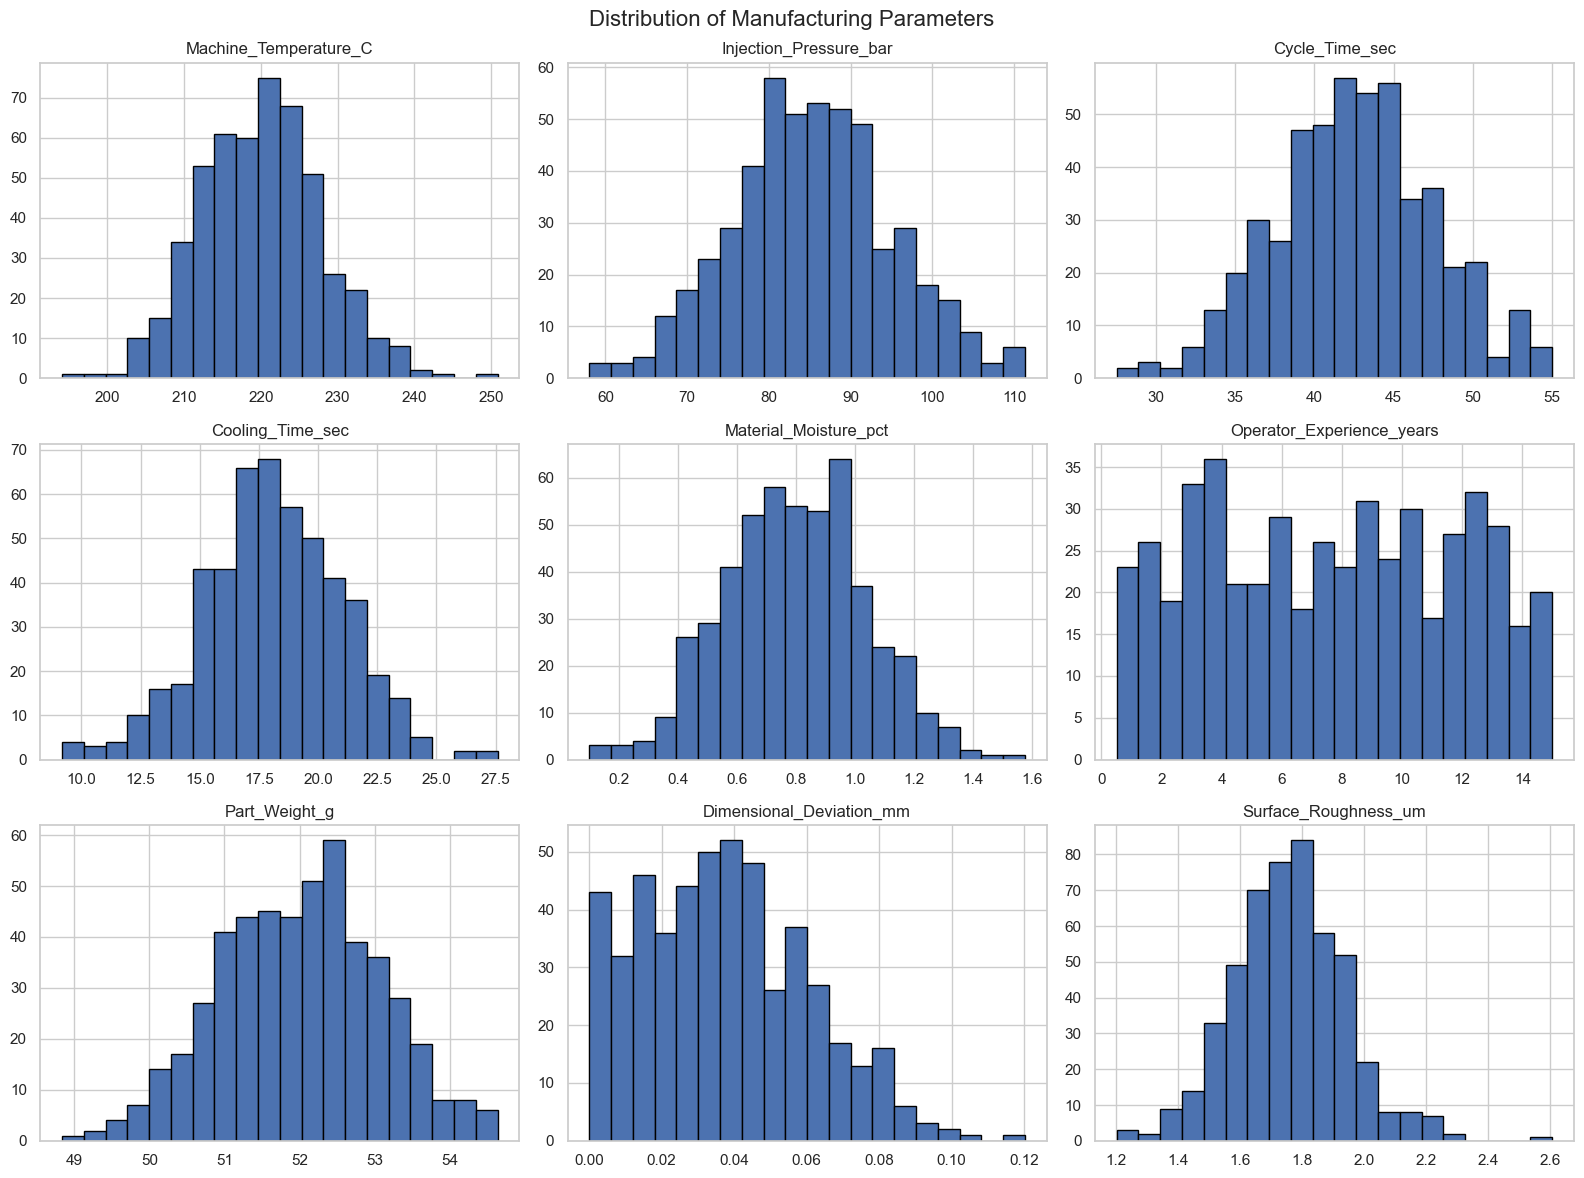

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

numerical_columns = df.select_dtypes(
    include=np.number
).columns

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Manufacturing Parameters",
    fontsize=16
)

plt.tight_layout()
plt.show()




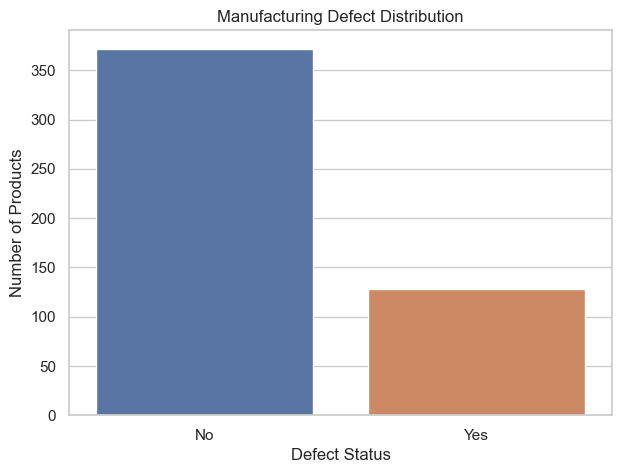

In [7]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Defect",
    hue="Defect",
    legend=False
)

plt.title("Manufacturing Defect Distribution")
plt.xlabel("Defect Status")
plt.ylabel("Number of Products")

plt.show()


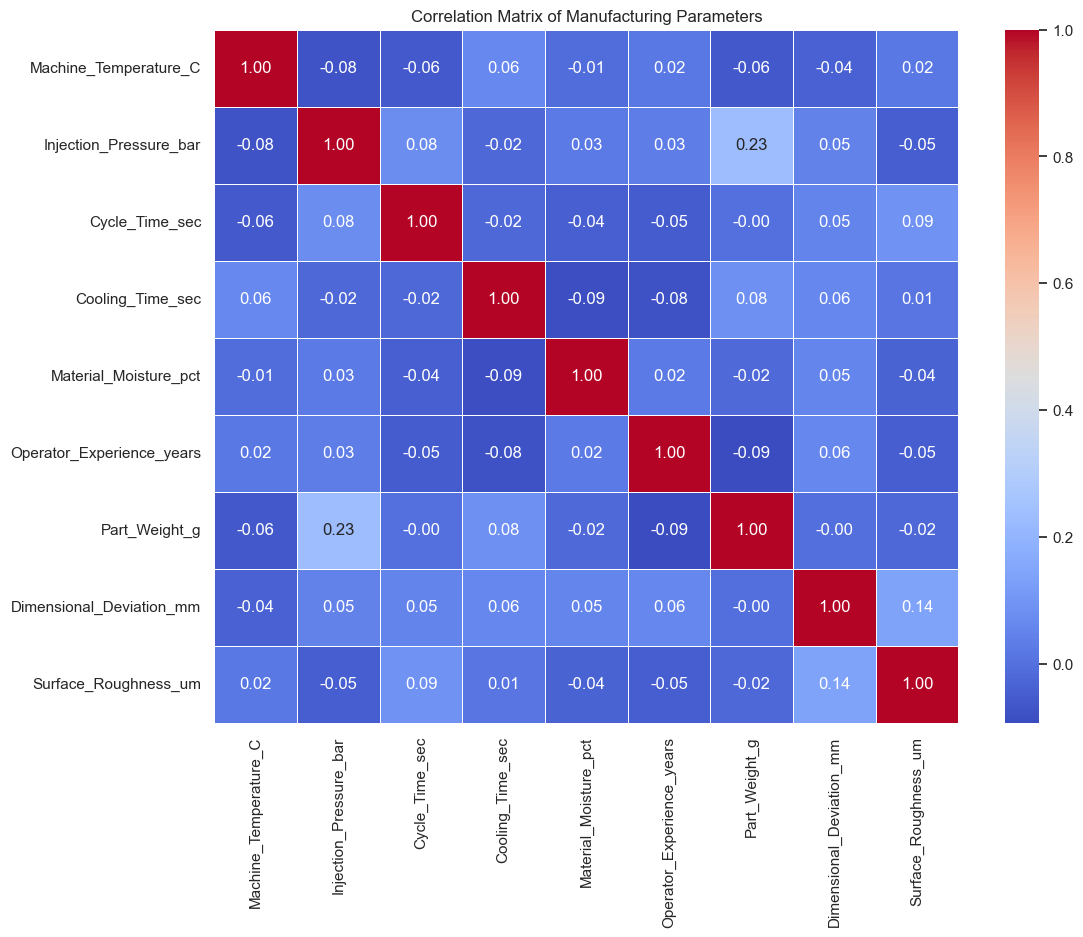

In [8]:

correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Manufacturing Parameters")

plt.show()


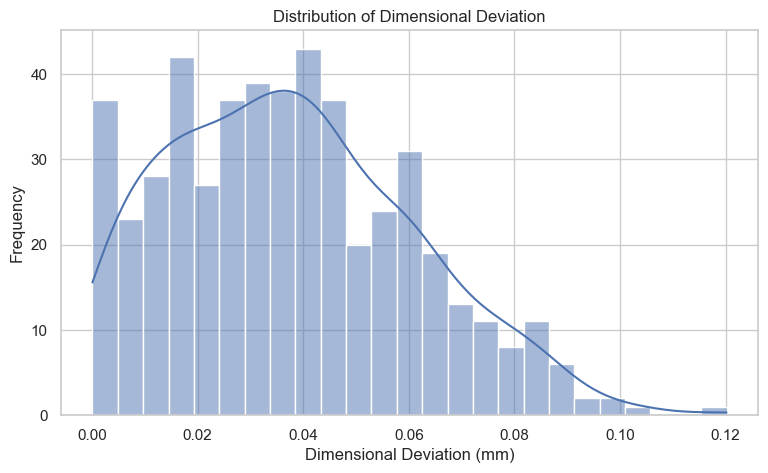

Mean dimensional deviation: 0.037629298695781674
Maximum dimensional deviation: 0.12019379222842555
Minimum dimensional deviation: 8.907664747502542e-05


In [9]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Dimensional_Deviation_mm",
    kde=True,
    bins=25
)

plt.title("Distribution of Dimensional Deviation")
plt.xlabel("Dimensional Deviation (mm)")
plt.ylabel("Frequency")

plt.show()

print("Mean dimensional deviation:",
      df["Dimensional_Deviation_mm"].mean())

print("Maximum dimensional deviation:",
      df["Dimensional_Deviation_mm"].max())

print("Minimum dimensional deviation:",
      df["Dimensional_Deviation_mm"].min())


In [10]:
# Statistical analysis of dimensional deviation

deviation = df["Dimensional_Deviation_mm"]

print("DIMENSIONAL DEVIATION ANALYSIS")
print("--------------------------------")

print("Mean:", deviation.mean())
print("Median:", deviation.median())
print("Standard Deviation:", deviation.std())
print("Minimum:", deviation.min())
print("Maximum:", deviation.max())

print("25th Percentile:", deviation.quantile(0.25))
print("50th Percentile:", deviation.quantile(0.50))
print("75th Percentile:", deviation.quantile(0.75))
print("95th Percentile:", deviation.quantile(0.95))

DIMENSIONAL DEVIATION ANALYSIS
--------------------------------
Mean: 0.037629298695781674
Median: 0.0357489031860053
Standard Deviation: 0.023123123492069977
Minimum: 8.907664747502542e-05
Maximum: 0.12019379222842555
25th Percentile: 0.018802210539924175
50th Percentile: 0.0357489031860053
75th Percentile: 0.05377982403141387
95th Percentile: 0.07989738584526666


In [11]:
# Categorizing dimensional deviation

bins = [0, 0.02, 0.04, 0.06, 0.08, float("inf")]

labels = [
    "0–0.02 mm",
    "0.02–0.04 mm",
    "0.04–0.06 mm",
    "0.06–0.08 mm",
    "Above 0.08 mm"
]

df["Deviation_Category"] = pd.cut(
    df["Dimensional_Deviation_mm"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

deviation_distribution = df["Deviation_Category"].value_counts(
    sort=False
)

print("DIMENSIONAL DEVIATION RANGE DISTRIBUTION")
print("----------------------------------------")
print(deviation_distribution)

print("\nPercentage Distribution:")
print((deviation_distribution / len(df) * 100).round(2))

DIMENSIONAL DEVIATION RANGE DISTRIBUTION
----------------------------------------
Deviation_Category
0–0.02 mm        132
0.02–0.04 mm     150
0.04–0.06 mm     131
0.06–0.08 mm      62
Above 0.08 mm     25
Name: count, dtype: int64

Percentage Distribution:
Deviation_Category
0–0.02 mm        26.4
0.02–0.04 mm     30.0
0.04–0.06 mm     26.2
0.06–0.08 mm     12.4
Above 0.08 mm     5.0
Name: count, dtype: float64


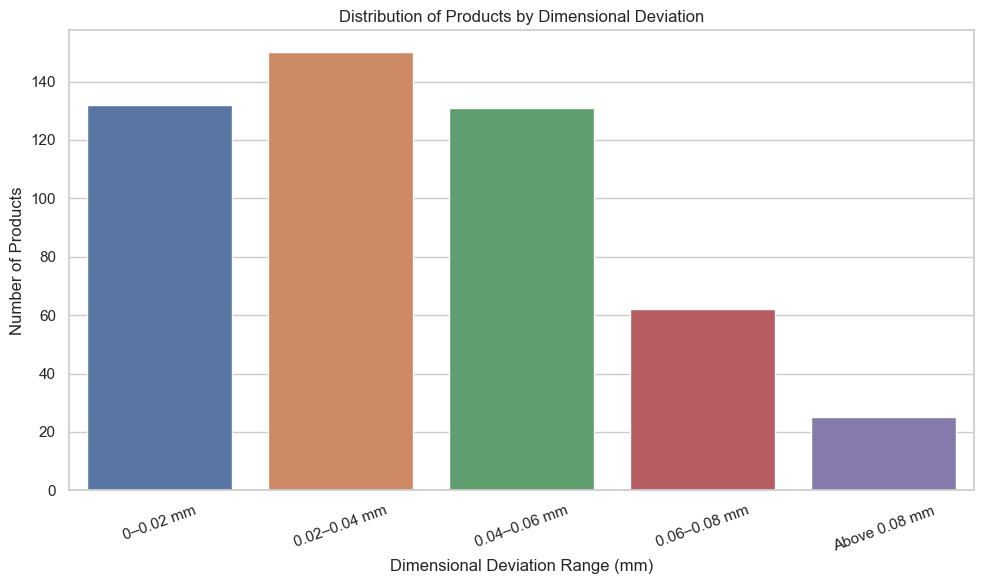

In [12]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Deviation_Category",
    hue="Deviation_Category",
    order=labels,
    legend=False
)

plt.title("Distribution of Products by Dimensional Deviation")
plt.xlabel("Dimensional Deviation Range (mm)")
plt.ylabel("Number of Products")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [13]:
# Compare dimensional deviation by defect status

defect_deviation = df.groupby("Defect")[
    "Dimensional_Deviation_mm"
].agg(["count", "mean", "median", "std", "min", "max"])

display(defect_deviation)

,count,mean,median,std,min,max
Defect,,,,,,
No,372,0.036692,0.034677,0.022480,0.000089,0.120194
Yes,128,0.040352,0.039100,0.024789,0.000196,0.104816


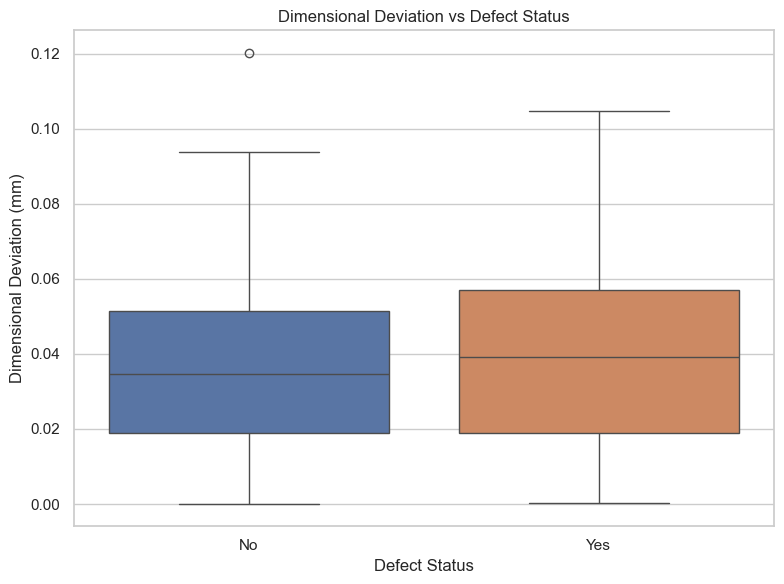

In [14]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Defect",
    y="Dimensional_Deviation_mm",
    hue="Defect",
    legend=False
)

plt.title("Dimensional Deviation vs Defect Status")
plt.xlabel("Defect Status")
plt.ylabel("Dimensional Deviation (mm)")

plt.tight_layout()
plt.show()

In [15]:
# Step 1: Feature Selection and Target Preparation

# Selecting input features
X = df.drop(columns=["Defect", "Deviation_Category"])

# Selecting target variable
y = df["Defect"]

# Display feature information
print("FEATURES (X)")
print("--------------------------")
print(X.head())

print("\nTARGET (y)")
print("--------------------------")
print(y.head())

# Check dimensions
print("\nFEATURES SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

# Check target distribution
print("\nTARGET DISTRIBUTION:")
print(y.value_counts())

FEATURES (X)
--------------------------
   Machine_Temperature_C  Injection_Pressure_bar  Cycle_Time_sec  \
0             223.973713               94.261775       48.996777   
1             218.893886              104.094166       46.623168   
2             225.181508               71.014324       42.298152   
3             232.184239               90.629692       38.765316   
4             218.126773               78.493574       45.491117   

   Cooling_Time_sec  Material_Moisture_pct  Operator_Experience_years  \
0         20.335083               0.631205                  12.304822   
1         16.346443               0.763870                  10.434447   
2         15.545403               0.601895                   2.101262   
3         17.989877               0.723010                   4.693218   
4         17.489446               0.326596                   4.992200   

   Part_Weight_g  Dimensional_Deviation_mm  Surface_Roughness_um  
0      51.827840                  0.028560   

In [16]:
# Step 2: Target Variable Encoding

# Convert categorical labels into numerical values
y = y.map({"No": 0, "Yes": 1})

# Display encoded target
print("ENCODED TARGET")
print("--------------------------")
print(y.head(10))

# Check unique values
print("\nUNIQUE TARGET VALUES:")
print(y.unique())

# Check target distribution
print("\nENCODED TARGET DISTRIBUTION:")
print(y.value_counts())

# Check for missing values
print("\nMISSING VALUES IN TARGET:")
print(y.isnull().sum())

ENCODED TARGET
--------------------------
0    0
1    0
2    0
3    1
4    0
5    0
6    0
7    0
8    0
9    0
Name: Defect, dtype: int64

UNIQUE TARGET VALUES:
[0 1]

ENCODED TARGET DISTRIBUTION:
Defect
0    372
1    128
Name: count, dtype: int64

MISSING VALUES IN TARGET:
0


In [17]:
# Step 3: Train-Test Split

from sklearn.model_selection import train_test_split

# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("TRAINING AND TESTING DATASET SHAPES")
print("-----------------------------------")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check class distribution in training data
print("\nTRAINING TARGET DISTRIBUTION:")
print(y_train.value_counts())

# Check class distribution in testing data
print("\nTESTING TARGET DISTRIBUTION:")
print(y_test.value_counts())

TRAINING AND TESTING DATASET SHAPES
-----------------------------------
X_train: (400, 9)
X_test: (100, 9)
y_train: (400,)
y_test: (100,)

TRAINING TARGET DISTRIBUTION:
Defect
0    298
1    102
Name: count, dtype: int64

TESTING TARGET DISTRIBUTION:
Defect
0    74
1    26
Name: count, dtype: int64


In [18]:
# Step 4: Feature Scaling using StandardScaler

from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Display scaled training data
print("SCALED TRAINING DATA:")
display(X_train_scaled.head())

# Display scaled testing data
print("\nSCALED TESTING DATA:")
display(X_test_scaled.head())

# Check mean and standard deviation
print("\nTRAINING DATA MEAN AFTER SCALING:")
print(X_train_scaled.mean().round(3))

print("\nTRAINING DATA STANDARD DEVIATION:")
print(X_train_scaled.std().round(3))

# Check dataset dimensions
print("\nSCALED DATASET SHAPES:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

SCALED TRAINING DATA:


,Machine_Temperature_C,Injection_Pressure_bar,Cycle_Time_sec,Cooling_Time_sec,Material_Moisture_pct,Operator_Experience_years,Part_Weight_g,Dimensional_Deviation_mm,Surface_Roughness_um
421,1.834577,-1.098690,0.943107,0.712181,1.233055,0.569328,0.469466,0.963274,0.817909
388,1.008308,0.560693,-0.110041,-0.529578,0.945224,0.260587,1.729910,-0.088629,-0.602634
288,0.321118,-0.117377,-1.259208,0.276423,-0.587423,-0.160288,0.626087,-0.993851,0.399260
276,0.237013,-0.791498,2.205080,-0.669767,0.728031,1.558748,-0.979404,0.544088,-0.955625
141,1.374489,1.667208,1.249991,1.387371,0.080561,0.962031,1.582057,0.294044,0.956838



SCALED TESTING DATA:


,Machine_Temperature_C,Injection_Pressure_bar,Cycle_Time_sec,Cooling_Time_sec,Material_Moisture_pct,Operator_Experience_years,Part_Weight_g,Dimensional_Deviation_mm,Surface_Roughness_um
258,0.488265,-0.926143,-0.856013,1.590705,-2.654742,-0.959868,-0.646043,0.423083,-0.606829
416,1.624971,0.578385,-0.084728,-0.848664,0.596270,-0.038556,1.190938,-0.504875,0.286544
120,0.844688,-0.856488,0.976526,0.067147,2.513628,-0.441905,-0.740584,-1.499602,1.428953
281,0.712367,-1.415581,-0.296756,-0.132445,-0.669895,0.523295,1.326569,-0.163755,-0.136866
1,-0.109259,1.913879,0.793436,-0.608191,-0.120748,0.652245,1.707476,2.266326,-1.250362



TRAINING DATA MEAN AFTER SCALING:
Machine_Temperature_C        0.0
Injection_Pressure_bar      -0.0
Cycle_Time_sec              -0.0
Cooling_Time_sec            -0.0
Material_Moisture_pct       -0.0
Operator_Experience_years   -0.0
Part_Weight_g                0.0
Dimensional_Deviation_mm    -0.0
Surface_Roughness_um         0.0
dtype: float64

TRAINING DATA STANDARD DEVIATION:
Machine_Temperature_C        1.001
Injection_Pressure_bar       1.001
Cycle_Time_sec               1.001
Cooling_Time_sec             1.001
Material_Moisture_pct        1.001
Operator_Experience_years    1.001
Part_Weight_g                1.001
Dimensional_Deviation_mm     1.001
Surface_Roughness_um         1.001
dtype: float64

SCALED DATASET SHAPES:
X_train_scaled: (400, 9)
X_test_scaled: (100, 9)


In [19]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
logistic_model = LogisticRegression(random_state=42)

# Train the model using scaled training data
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

print("\nModel Parameters:")
print(logistic_model)

Logistic Regression Model Trained Successfully!

Model Parameters:
LogisticRegression(random_state=42)


In [20]:
# Make predictions using the trained Logistic Regression model
y_pred = logistic_model.predict(X_test_scaled)

print("PREDICTIONS GENERATED SUCCESSFULLY!")

print("\nFirst 20 Predicted Values:")
print(y_pred[:20])

print("\nFirst 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nTotal Predictions:", len(y_pred))

PREDICTIONS GENERATED SUCCESSFULLY!

First 20 Predicted Values:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Actual Values:
[0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0]

Total Predictions: 100


In [21]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX:")
print(cm)

# Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("\nMODEL PERFORMANCE:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

# Detailed Classification Report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Defective", "Defective"]
))

CONFUSION MATRIX:
[[73  1]
 [26  0]]

MODEL PERFORMANCE:
Accuracy: 0.73
Precision: 0.0
Recall: 0.0
F1-Score: 0.0

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

Non-Defective       0.74      0.99      0.84        74
    Defective       0.00      0.00      0.00        26

     accuracy                           0.73       100
    macro avg       0.37      0.49      0.42       100
 weighted avg       0.55      0.73      0.62       100



In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Initialize balanced Logistic Regression
balanced_model = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

# Train the model
balanced_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_balanced = balanced_model.predict(X_test_scaled)

# Evaluate the model
print("BALANCED LOGISTIC REGRESSION RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred_balanced), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_balanced, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_balanced, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_test, y_pred_balanced, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))

BALANCED LOGISTIC REGRESSION RESULTS

Confusion Matrix:
[[33 41]
 [13 13]]

Accuracy: 0.46
Precision: 0.2407
Recall: 0.5
F1-Score: 0.325

Classification Report:
               precision    recall  f1-score   support

Non-Defective       0.72      0.45      0.55        74
    Defective       0.24      0.50      0.33        26

     accuracy                           0.46       100
    macro avg       0.48      0.47      0.44       100
 weighted avg       0.59      0.46      0.49       100



In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Split training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Scale data without validation leakage
validation_scaler = StandardScaler()

X_subtrain_scaled = validation_scaler.fit_transform(X_subtrain)
X_val_scaled = validation_scaler.transform(X_val)

# Train balanced Logistic Regression
validation_model = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

validation_model.fit(X_subtrain_scaled, y_subtrain)

# Get probability of defect (class 1)
y_val_prob = validation_model.predict_proba(X_val_scaled)[:, 1]

# Evaluate different thresholds
thresholds = [0.30, 0.40, 0.50, 0.60]

print("THRESHOLD COMPARISON ON VALIDATION DATA")

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
    print("Precision:", round(precision_score(
        y_val, y_val_pred, zero_division=0
    ), 3))
    print("Recall:", round(recall_score(
        y_val, y_val_pred, zero_division=0
    ), 3))
    print("F1-Score:", round(f1_score(
        y_val, y_val_pred, zero_division=0
    ), 3))

THRESHOLD COMPARISON ON VALIDATION DATA

Threshold: 0.3
Accuracy: 0.25
Precision: 0.237
Recall: 0.9
F1-Score: 0.375

Threshold: 0.4
Accuracy: 0.35
Precision: 0.242
Recall: 0.75
F1-Score: 0.366

Threshold: 0.5
Accuracy: 0.537
Precision: 0.282
Recall: 0.55
F1-Score: 0.373

Threshold: 0.6
Accuracy: 0.725
Precision: 0.417
Recall: 0.25
F1-Score: 0.312


In [24]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Selected decision threshold
selected_threshold = 0.30

# Predict defect probabilities on test data
y_test_prob = balanced_model.predict_proba(X_test_scaled)[:, 1]

# Convert probabilities into binary predictions
y_pred_final = (y_test_prob >= selected_threshold).astype(int)

# Evaluate final threshold-based predictions
print("FINAL MODEL EVALUATION")
print("Selected Threshold:", selected_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred_final), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_final, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_final, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_test, y_pred_final, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))

FINAL MODEL EVALUATION
Selected Threshold: 0.3

Confusion Matrix:
[[ 5 69]
 [ 0 26]]

Accuracy: 0.31
Precision: 0.2737
Recall: 1.0
F1-Score: 0.4298

Classification Report:
               precision    recall  f1-score   support

Non-Defective       1.00      0.07      0.13        74
    Defective       0.27      1.00      0.43        26

     accuracy                           0.31       100
    macro avg       0.64      0.53      0.28       100
 weighted avg       0.81      0.31      0.21       100



In [25]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

print("\nModel Parameters:")
print(rf_model)

Random Forest Model Trained Successfully!

Model Parameters:
RandomForestClassifier(class_weight='balanced', random_state=42)


In [26]:
# Generate predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("RANDOM FOREST PREDICTIONS GENERATED SUCCESSFULLY!")

print("\nFirst 20 Predicted Values:")
print(y_pred_rf[:20])

print("\nFirst 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nTotal Predictions:", len(y_pred_rf))

RANDOM FOREST PREDICTIONS GENERATED SUCCESSFULLY!

First 20 Predicted Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]

First 20 Actual Values:
[0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0]

Total Predictions: 100


In [27]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("RANDOM FOREST CONFUSION MATRIX:")
print(cm_rf)

# Calculate evaluation metrics
print("\nRANDOM FOREST PERFORMANCE:")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_rf, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_rf, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nCLASSIFICATION REPORT:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))

RANDOM FOREST CONFUSION MATRIX:
[[66  8]
 [24  2]]

RANDOM FOREST PERFORMANCE:
Accuracy: 0.68
Precision: 0.2
Recall: 0.0769
F1-Score: 0.1111

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

Non-Defective       0.73      0.89      0.80        74
    Defective       0.20      0.08      0.11        26

     accuracy                           0.68       100
    macro avg       0.47      0.48      0.46       100
 weighted avg       0.59      0.68      0.62       100



RANDOM FOREST FEATURE IMPORTANCE:


,Feature,Importance
1,Injection_Pressure_bar,0.153040
4,Material_Moisture_pct,0.135263
0,Machine_Temperature_C,0.115878
5,Operator_Experience_years,0.105325
8,Surface_Roughness_um,0.103542
6,Part_Weight_g,0.100920
7,Dimensional_Deviation_mm,0.097371
2,Cycle_Time_sec,0.095635
3,Cooling_Time_sec,0.093026


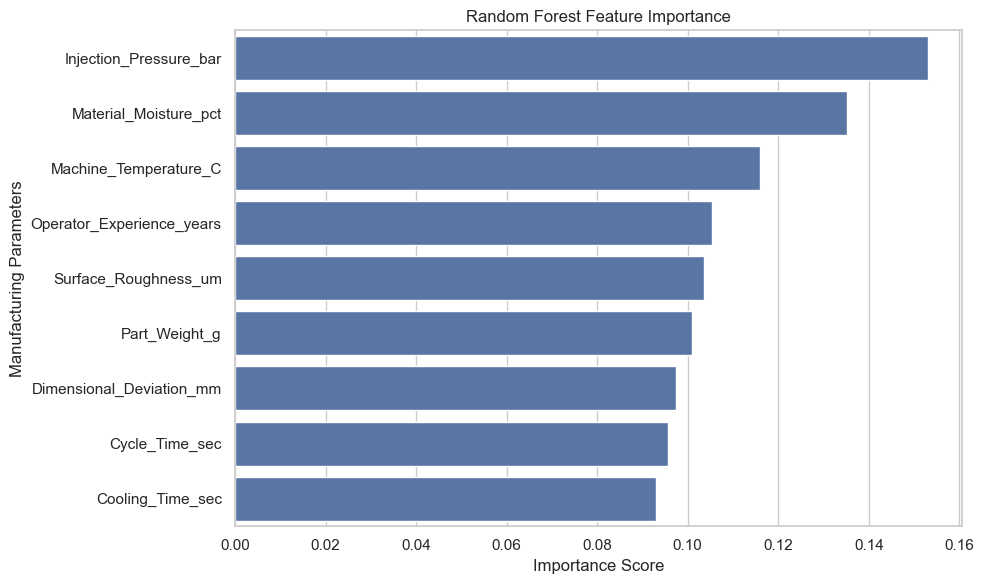

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE:")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Manufacturing Parameters")
plt.tight_layout()
plt.show()

In [29]:

from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1"
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("PERMUTATION FEATURE IMPORTANCE:")
display(permutation_importance_df)


PERMUTATION FEATURE IMPORTANCE:


,Feature,Importance,Std
0,Machine_Temperature_C,0.042616,0.022209
8,Surface_Roughness_um,0.024364,0.025897
7,Dimensional_Deviation_mm,0.017683,0.036837
6,Part_Weight_g,0.016921,0.027483
1,Injection_Pressure_bar,-0.004996,0.075768
4,Material_Moisture_pct,-0.023366,0.043540
3,Cooling_Time_sec,-0.023424,0.054772
5,Operator_Experience_years,-0.030428,0.030407
2,Cycle_Time_sec,-0.044889,0.022137


In [30]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

rf_parameter_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("BEST RANDOM FOREST PARAMETERS:")
print(rf_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1 SCORE:")
print(rf_grid_search.best_score_)


Fitting 5 folds for each of 216 candidates, totalling 1080 fits


C:\Users\dell\anaconda3\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


BEST RANDOM FOREST PARAMETERS:
{'class_weight': 'balanced_subsample', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}

BEST CROSS-VALIDATION F1 SCORE:
0.2991666666666667


In [31]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Retrieve the optimized Random Forest model
best_rf_model = rf_grid_search.best_estimator_

# Generate predictions
y_pred_optimized_rf = best_rf_model.predict(X_test)

# Calculate confusion matrix
cm_optimized = confusion_matrix(y_test, y_pred_optimized_rf)

print("OPTIMIZED RANDOM FOREST - CONFUSION MATRIX:")
print(cm_optimized)

# Calculate evaluation metrics
print("\nOPTIMIZED RANDOM FOREST - PERFORMANCE:")

print("Accuracy:",
      accuracy_score(y_test, y_pred_optimized_rf))

print("Precision:",
      precision_score(y_test, y_pred_optimized_rf, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_optimized_rf, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_optimized_rf, zero_division=0))

# Detailed classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred_optimized_rf,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))


OPTIMIZED RANDOM FOREST - CONFUSION MATRIX:
[[54 20]
 [20  6]]

OPTIMIZED RANDOM FOREST - PERFORMANCE:
Accuracy: 0.6
Precision: 0.23076923076923078
Recall: 0.23076923076923078
F1 Score: 0.23076923076923078

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

Non-Defective       0.73      0.73      0.73        74
    Defective       0.23      0.23      0.23        26

     accuracy                           0.60       100
    macro avg       0.48      0.48      0.48       100
 weighted avg       0.60      0.60      0.60       100



In [32]:
import xgboost as xgb

print("XGBoost Version:", xgb.__version__)
print("XGBoost Imported Successfully!")

XGBoost Version: 3.2.0
XGBoost Imported Successfully!


In [33]:

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")
print("\nModel Parameters:")
print(xgb_model)


XGBoost Model Trained Successfully!

Model Parameters:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)


In [34]:

# Generate predictions using XGBoost

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Predictions:")
print(y_pred_xgb[:20])

print("\nActual Values:")
print(y_test.values[:20])

print("\nTotal Predictions:", len(y_pred_xgb))


XGBoost Predictions:
[0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0]

Actual Values:
[0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0]

Total Predictions: 100


In [35]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("XGBOOST - CONFUSION MATRIX:")
print(cm_xgb)

# Calculate performance metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb, zero_division=0)
recall_xgb = recall_score(y_test, y_pred_xgb, zero_division=0)
f1_xgb = f1_score(y_test, y_pred_xgb, zero_division=0)

print("\nXGBOOST - PERFORMANCE:")
print("Accuracy:", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall:", recall_xgb)
print("F1 Score:", f1_xgb)

# Classification report
print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Non-Defective", "Defective"],
        zero_division=0
    )
)


XGBOOST - CONFUSION MATRIX:
[[65  9]
 [21  5]]

XGBOOST - PERFORMANCE:
Accuracy: 0.7
Precision: 0.35714285714285715
Recall: 0.19230769230769232
F1 Score: 0.25

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

Non-Defective       0.76      0.88      0.81        74
    Defective       0.36      0.19      0.25        26

     accuracy                           0.70       100
    macro avg       0.56      0.54      0.53       100
 weighted avg       0.65      0.70      0.67       100



In [36]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

# Define parameter combinations
xgb_parameter_grid = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_weight": [1, 3],
    "scale_pos_weight": [1, 2.92]
}

# Stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize Grid Search
xgb_grid_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1
    ),
    param_grid=xgb_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Fit Grid Search
xgb_grid_search.fit(X_train, y_train)

print("BEST XGBOOST PARAMETERS:")
print(xgb_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1 SCORE:")
print(xgb_grid_search.best_score_)


Fitting 5 folds for each of 72 candidates, totalling 360 fits
BEST XGBOOST PARAMETERS:
{'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 200, 'scale_pos_weight': 2.92}

BEST CROSS-VALIDATION F1 SCORE:
0.408034188034188


In [37]:
# Retrieve the best XGBoost model
best_xgb_model = xgb_grid_search.best_estimator_

# Generate predictions on test data
y_pred_xgb_optimized = best_xgb_model.predict(X_test)

print("Optimized XGBoost Model Predictions:")
print(y_pred_xgb_optimized[:20])

print("\nActual Test Labels:")
print(y_test.values[:20])

print("\nTotal Predictions:", len(y_pred_xgb_optimized))

Optimized XGBoost Model Predictions:
[0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1]

Actual Test Labels:
[0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0]

Total Predictions: 100


In [38]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate confusion matrix
cm_xgb_optimized = confusion_matrix(
    y_test, y_pred_xgb_optimized
)

# Calculate evaluation metrics
accuracy_xgb_optimized = accuracy_score(
    y_test, y_pred_xgb_optimized
)

precision_xgb_optimized = precision_score(
    y_test, y_pred_xgb_optimized, zero_division=0
)

recall_xgb_optimized = recall_score(
    y_test, y_pred_xgb_optimized, zero_division=0
)

f1_xgb_optimized = f1_score(
    y_test, y_pred_xgb_optimized, zero_division=0
)

# Display results
print("OPTIMIZED XGBOOST MODEL EVALUATION")

print("\nConfusion Matrix:")
print(cm_xgb_optimized)

print("\nAccuracy:", accuracy_xgb_optimized)
print("Precision:", precision_xgb_optimized)
print("Recall:", recall_xgb_optimized)
print("F1-Score:", f1_xgb_optimized)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb_optimized,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))

OPTIMIZED XGBOOST MODEL EVALUATION

Confusion Matrix:
[[46 28]
 [16 10]]

Accuracy: 0.56
Precision: 0.2631578947368421
Recall: 0.38461538461538464
F1-Score: 0.3125

Classification Report:
               precision    recall  f1-score   support

Non-Defective       0.74      0.62      0.68        74
    Defective       0.26      0.38      0.31        26

     accuracy                           0.56       100
    macro avg       0.50      0.50      0.49       100
 weighted avg       0.62      0.56      0.58       100



In [39]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create cross-validation strategy
xgb_cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities
xgb_oof_probabilities = cross_val_predict(
    best_xgb_model,
    X_train,
    y_train,
    cv=xgb_cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Test different decision thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

print("XGBOOST THRESHOLD COMPARISON\n")

for threshold in thresholds:

    y_oof_pred = (
        xgb_oof_probabilities >= threshold
    ).astype(int)

    print("Threshold:", threshold)
    print("Accuracy:", round(
        accuracy_score(y_train, y_oof_pred), 3
    ))
    print("Precision:", round(
        precision_score(y_train, y_oof_pred, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_train, y_oof_pred, zero_division=0), 3
    ))
    print("F1-Score:", round(
        f1_score(y_train, y_oof_pred, zero_division=0), 3
    ))
    print("-" * 40)

XGBOOST THRESHOLD COMPARISON

Threshold: 0.2
Accuracy: 0.315
Precision: 0.264
Recall: 0.941
F1-Score: 0.412
----------------------------------------
Threshold: 0.25
Accuracy: 0.355
Precision: 0.265
Recall: 0.863
F1-Score: 0.406
----------------------------------------
Threshold: 0.3
Accuracy: 0.425
Precision: 0.282
Recall: 0.814
F1-Score: 0.419
----------------------------------------
Threshold: 0.35
Accuracy: 0.477
Precision: 0.295
Recall: 0.755
F1-Score: 0.424
----------------------------------------
Threshold: 0.4
Accuracy: 0.522
Precision: 0.299
Recall: 0.647
F1-Score: 0.409
----------------------------------------
Threshold: 0.45
Accuracy: 0.578
Precision: 0.319
Recall: 0.578
F1-Score: 0.411
----------------------------------------
Threshold: 0.5
Accuracy: 0.652
Precision: 0.361
Recall: 0.471
F1-Score: 0.409
----------------------------------------
Threshold: 0.55
Accuracy: 0.68
Precision: 0.356
Recall: 0.314
F1-Score: 0.333
----------------------------------------
Threshold: 0.6


In [40]:
# Selected decision threshold
selected_xgb_threshold = 0.35

# Generate defect probabilities on test data
y_test_xgb_prob = best_xgb_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_pred_xgb_threshold = (
    y_test_xgb_prob >= selected_xgb_threshold
).astype(int)

# Evaluate the model
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

cm_xgb_threshold = confusion_matrix(
    y_test, y_pred_xgb_threshold
)

accuracy_xgb_threshold = accuracy_score(
    y_test, y_pred_xgb_threshold
)

precision_xgb_threshold = precision_score(
    y_test, y_pred_xgb_threshold, zero_division=0
)

recall_xgb_threshold = recall_score(
    y_test, y_pred_xgb_threshold, zero_division=0
)

f1_xgb_threshold = f1_score(
    y_test, y_pred_xgb_threshold, zero_division=0
)

print("XGBOOST MODEL WITH OPTIMIZED THRESHOLD")
print("\nSelected Threshold:", selected_xgb_threshold)

print("\nConfusion Matrix:")
print(cm_xgb_threshold)

print("\nAccuracy:", accuracy_xgb_threshold)
print("Precision:", precision_xgb_threshold)
print("Recall:", recall_xgb_threshold)
print("F1-Score:", f1_xgb_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb_threshold,
    target_names=["Non-Defective", "Defective"],
    zero_division=0
))

XGBOOST MODEL WITH OPTIMIZED THRESHOLD

Selected Threshold: 0.35

Confusion Matrix:
[[27 47]
 [ 5 21]]

Accuracy: 0.48
Precision: 0.3088235294117647
Recall: 0.8076923076923077
F1-Score: 0.44680851063829785

Classification Report:
               precision    recall  f1-score   support

Non-Defective       0.84      0.36      0.51        74
    Defective       0.31      0.81      0.45        26

     accuracy                           0.48       100
    macro avg       0.58      0.59      0.48       100
 weighted avg       0.70      0.48      0.49       100



In [41]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Balanced LR (Threshold 0.30)",
        "Random Forest",
        "Optimized Random Forest",
        "Baseline XGBoost",
        "Optimized XGBoost",
        "Optimized XGBoost (Threshold 0.35)"
    ],

    "Accuracy": [
        0.73, 0.46, 0.31, 0.68,
        0.60, 0.70, 0.56, 0.48
    ],

    "Precision": [
        0.00, 0.2407, 0.2737, 0.20,
        0.2308, 0.3571, 0.2632, 0.3088
    ],

    "Recall": [
        0.00, 0.50, 1.00, 0.0769,
        0.2308, 0.1923, 0.3846, 0.8077
    ],

    "F1-Score": [
        0.00, 0.325, 0.4298, 0.1111,
        0.2308, 0.25, 0.3125, 0.4468
    ]
})

model_comparison = model_comparison.sort_values(
    by="F1-Score",
    ascending=False
)

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
7,Optimized XGBoost (Threshold 0.35),0.48,0.3088,0.8077,0.4468
2,Balanced LR (Threshold 0.30),0.31,0.2737,1.0000,0.4298
1,Balanced Logistic Regression,0.46,0.2407,0.5000,0.3250
6,Optimized XGBoost,0.56,0.2632,0.3846,0.3125
5,Baseline XGBoost,0.70,0.3571,0.1923,0.2500
4,Optimized Random Forest,0.60,0.2308,0.2308,0.2308
3,Random Forest,0.68,0.2000,0.0769,0.1111
0,Logistic Regression,0.73,0.0000,0.0000,0.0000


OPTIMIZED XGBOOST FEATURE IMPORTANCE


,Feature,Importance
4,Material_Moisture_pct,0.126425
1,Injection_Pressure_bar,0.124701
0,Machine_Temperature_C,0.117934
8,Surface_Roughness_um,0.112607
2,Cycle_Time_sec,0.109211
5,Operator_Experience_years,0.103950
7,Dimensional_Deviation_mm,0.103664
6,Part_Weight_g,0.100873
3,Cooling_Time_sec,0.100636


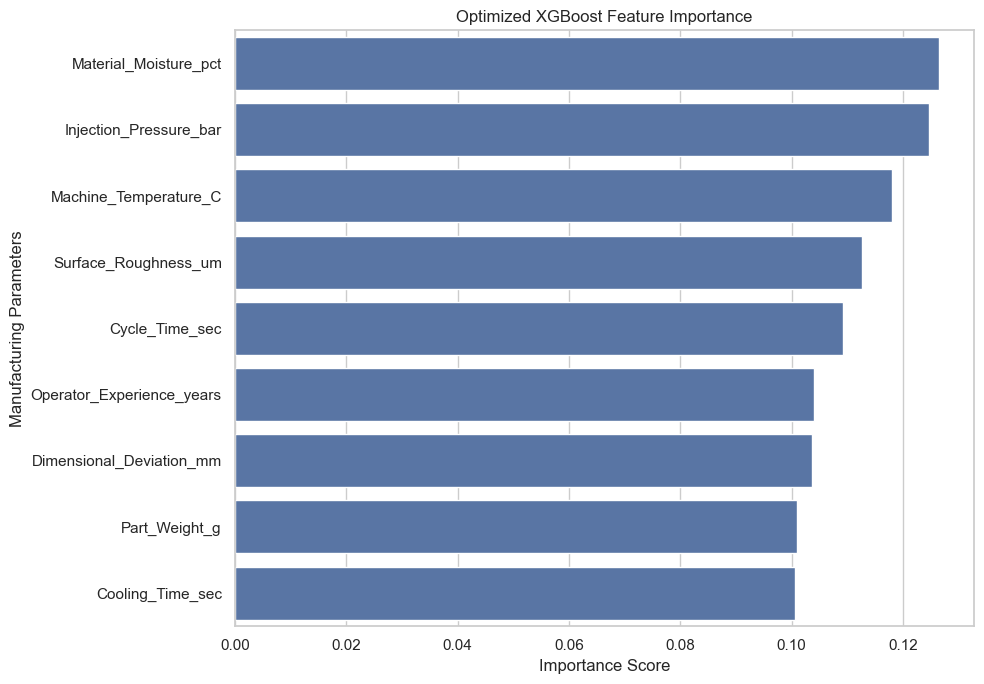

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from optimized XGBoost
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb_model.feature_importances_
})

# Sort features by importance
xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("OPTIMIZED XGBOOST FEATURE IMPORTANCE")
display(xgb_importance)

# Visualize feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature"
)

plt.title("Optimized XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Manufacturing Parameters")
plt.tight_layout()
plt.show()

XGBOOST PERMUTATION FEATURE IMPORTANCE


,Feature,Importance,Std
7,Dimensional_Deviation_mm,0.006174,0.017702
0,Machine_Temperature_C,0.002115,0.046254
6,Part_Weight_g,-0.001865,0.029435
5,Operator_Experience_years,-0.003989,0.033867
3,Cooling_Time_sec,-0.009520,0.022276
2,Cycle_Time_sec,-0.024926,0.032001
1,Injection_Pressure_bar,-0.026962,0.042542
8,Surface_Roughness_um,-0.041854,0.021801
4,Material_Moisture_pct,-0.068980,0.039517


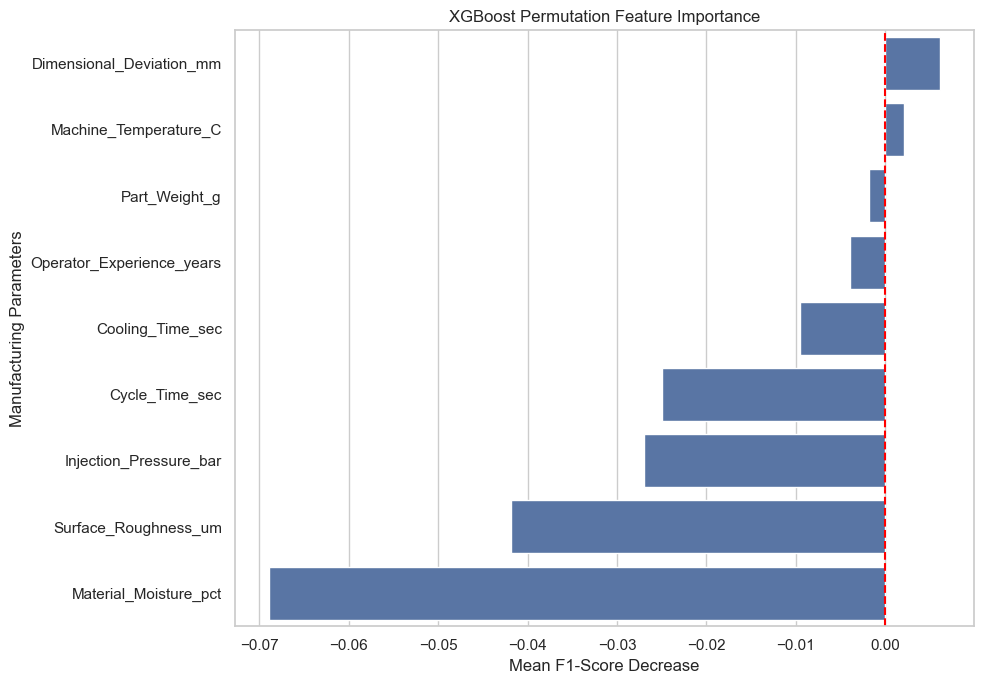

In [43]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
xgb_permutation = permutation_importance(
    best_xgb_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="f1"
)

# Create results DataFrame
xgb_permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": xgb_permutation.importances_mean,
    "Std": xgb_permutation.importances_std
})

# Sort results
xgb_permutation_df = xgb_permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print("XGBOOST PERMUTATION FEATURE IMPORTANCE")
display(xgb_permutation_df)

# Visualize results
plt.figure(figsize=(10, 7))

sns.barplot(
    data=xgb_permutation_df,
    x="Importance",
    y="Feature"
)

plt.axvline(0, linestyle="--", color="red")

plt.title("XGBoost Permutation Feature Importance")
plt.xlabel("Mean F1-Score Decrease")
plt.ylabel("Manufacturing Parameters")

plt.tight_layout()
plt.show()

THRESHOLD-AWARE XGBOOST PERMUTATION IMPORTANCE


,Feature,Importance,Std
8,Surface_Roughness_um,0.040189,0.020111
1,Injection_Pressure_bar,0.032728,0.031955
0,Machine_Temperature_C,0.032464,0.027919
6,Part_Weight_g,0.029386,0.024439
3,Cooling_Time_sec,0.027928,0.015219
7,Dimensional_Deviation_mm,0.019600,0.013167
5,Operator_Experience_years,0.013775,0.021348
4,Material_Moisture_pct,0.013696,0.033575
2,Cycle_Time_sec,0.006313,0.009574


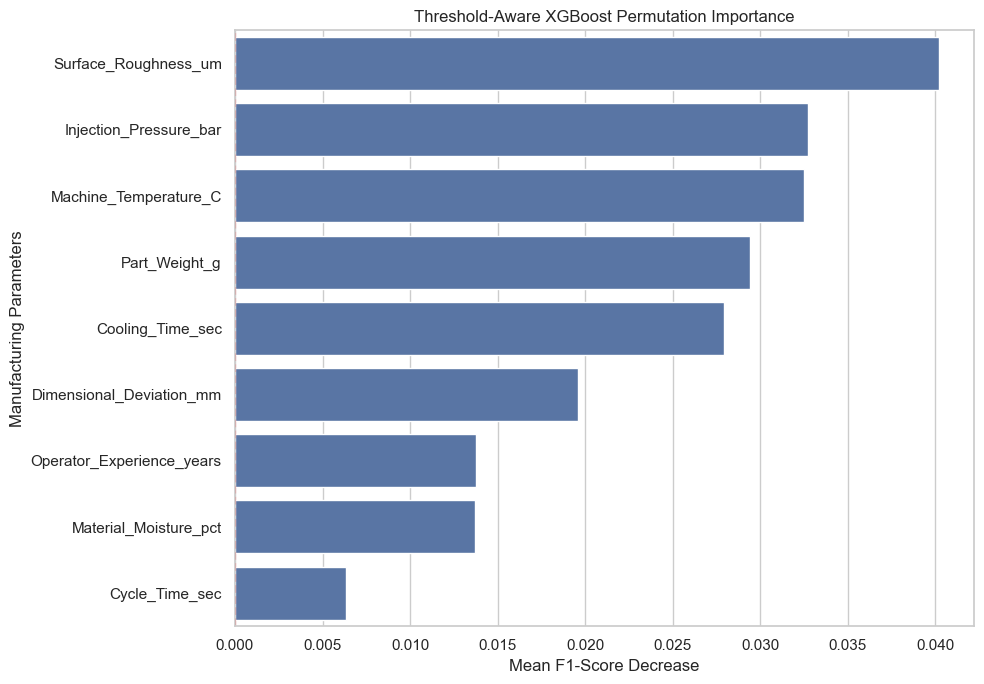

In [44]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Custom scoring function using threshold 0.35
def xgb_threshold_f1(estimator, X_data, y_data):

    probabilities = estimator.predict_proba(X_data)[:, 1]

    predictions = (probabilities >= 0.35).astype(int)

    return f1_score(y_data, predictions, zero_division=0)


# Calculate threshold-aware permutation importance
xgb_threshold_permutation = permutation_importance(
    best_xgb_model,
    X_test,
    y_test,
    scoring=xgb_threshold_f1,
    n_repeats=30,
    random_state=42
)


# Create DataFrame
xgb_threshold_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": xgb_threshold_permutation.importances_mean,
    "Std": xgb_threshold_permutation.importances_std
})


# Sort results
xgb_threshold_importance_df = (
    xgb_threshold_importance_df.sort_values(
        by="Importance",
        ascending=False
    )
)


print("THRESHOLD-AWARE XGBOOST PERMUTATION IMPORTANCE")

display(xgb_threshold_importance_df)


# Visualize
plt.figure(figsize=(10, 7))

sns.barplot(
    data=xgb_threshold_importance_df,
    x="Importance",
    y="Feature"
)

plt.axvline(0, linestyle="--", color="red")

plt.title("Threshold-Aware XGBoost Permutation Importance")
plt.xlabel("Mean F1-Score Decrease")
plt.ylabel("Manufacturing Parameters")

plt.tight_layout()
plt.show()

In [45]:
from pathlib import Path

# Define project directory
project_dir = Path("..")

# Define folder structure
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "reports/figures",
    "models",
    "src"
]

# Create project folders
for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

print("PROJECT FOLDER STRUCTURE CREATED SUCCESSFULLY!")

print("\nProject Location:")
print(project_dir.resolve())

print("\nCreated Folders:")

for folder in folders:
    print(f"  {folder}/")

PROJECT FOLDER STRUCTURE CREATED SUCCESSFULLY!

Project Location:
D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning

Created Folders:
  data/raw/
  data/processed/
  notebooks/
  reports/figures/
  models/
  src/


In [46]:
# Save processed manufacturing dataset
processed_data_dir = project_dir / "data" / "processed"
processed_data_dir.mkdir(parents=True, exist_ok=True)

processed_dataset_path = (
    processed_data_dir / "manufacturing_data_with_deviation_category.csv"
)

df.to_csv(processed_dataset_path, index=False)

print("PROCESSED DATASET SAVED SUCCESSFULLY!")
print("Dataset Location:", processed_dataset_path.resolve())
print("Dataset Shape:", df.shape)

PROCESSED DATASET SAVED SUCCESSFULLY!
Dataset Location: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\data\processed\manufacturing_data_with_deviation_category.csv
Dataset Shape: (500, 11)


In [47]:
# Check dataset columns
print("TOTAL COLUMNS:", len(df.columns))

print("\nDATASET COLUMN NAMES:")

for column in df.columns:
    print(column)

print("\nDATASET SHAPE:", df.shape)

print("\nFIRST FIVE ROWS:")
display(df.head())

TOTAL COLUMNS: 11

DATASET COLUMN NAMES:
Machine_Temperature_C
Injection_Pressure_bar
Cycle_Time_sec
Cooling_Time_sec
Material_Moisture_pct
Operator_Experience_years
Part_Weight_g
Dimensional_Deviation_mm
Surface_Roughness_um
Defect
Deviation_Category

DATASET SHAPE: (500, 11)

FIRST FIVE ROWS:


,Machine_Temperature_C,Injection_Pressure_bar,Cycle_Time_sec,Cooling_Time_sec,Material_Moisture_pct,Operator_Experience_years,Part_Weight_g,Dimensional_Deviation_mm,Surface_Roughness_um,Defect,Deviation_Category
0,223.973713,94.261775,48.996777,20.335083,0.631205,12.304822,51.827840,0.028560,1.796697,No,0.02–0.04 mm
1,218.893886,104.094166,46.623168,16.346443,0.763870,10.434447,53.829974,0.089242,1.528595,No,Above 0.08 mm
2,225.181508,71.014324,42.298152,15.545403,0.601895,2.101262,51.045095,0.020284,1.526276,No,0.02–0.04 mm
3,232.184239,90.629692,38.765316,17.989877,0.723010,4.693218,52.527344,0.029715,1.948231,Yes,0.02–0.04 mm
4,218.126773,78.493574,45.491117,17.489446,0.326596,4.992200,51.073851,0.077807,1.803150,No,0.06–0.08 mm


In [48]:
# Create a separate copy of the original dataset
raw_df = df.drop(columns=["Deviation_Category"])

# Save the corrected raw dataset
dataset_path = (
    project_dir / "data" / "raw" /
    "manufacturing_data_synthetic.csv"
)

raw_df.to_csv(dataset_path, index=False)

# Verify the saved dataset
print("RAW DATASET SAVED SUCCESSFULLY!")

print("\nRaw Dataset Shape:", raw_df.shape)

print("\nTotal Columns:", len(raw_df.columns))

print("\nColumn Names:")
print(raw_df.columns.tolist())

print("\nDefect Distribution:")
print(raw_df["Defect"].value_counts())

RAW DATASET SAVED SUCCESSFULLY!

Raw Dataset Shape: (500, 10)

Total Columns: 10

Column Names:
['Machine_Temperature_C', 'Injection_Pressure_bar', 'Cycle_Time_sec', 'Cooling_Time_sec', 'Material_Moisture_pct', 'Operator_Experience_years', 'Part_Weight_g', 'Dimensional_Deviation_mm', 'Surface_Roughness_um', 'Defect']

Defect Distribution:
Defect
No     372
Yes    128
Name: count, dtype: int64


In [49]:
# Check currently available figures

import matplotlib.pyplot as plt

print("Number of currently open figures:",
      len(plt.get_fignums()))

print("\nFigure numbers:",
      plt.get_fignums())

Number of currently open figures: 0

Figure numbers: []


In [50]:
from pathlib import Path

figures_dir = (
    project_dir / "reports" / "figures"
)

figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures folder location:")
print(figures_dir.resolve())

print("\nFolder exists:", figures_dir.exists())

Figures folder location:
D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\reports\figures

Folder exists: True


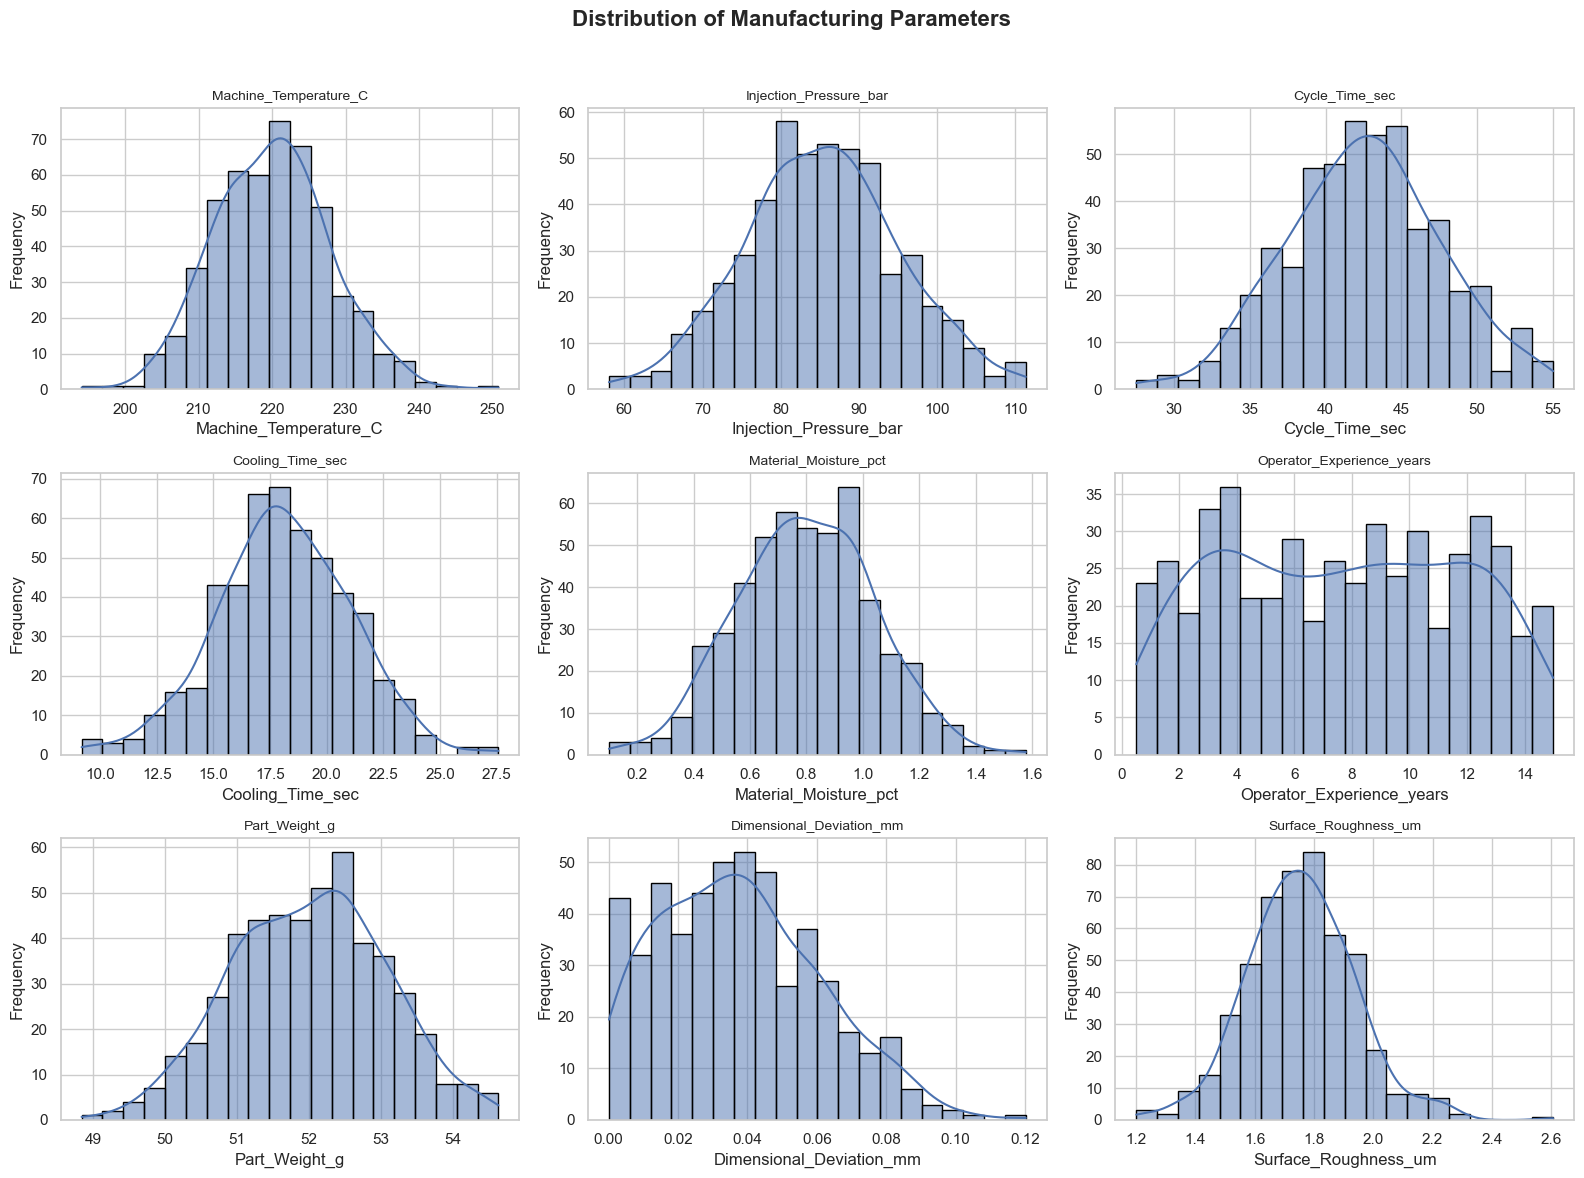


FIGURE 01 SAVED SUCCESSFULLY!
D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\reports\figures\01_manufacturing_parameter_distributions.png


In [51]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
numerical_columns = raw_df.select_dtypes(
    include="number"
).columns

# Create 3x3 subplot layout
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

axes = axes.flatten()

# Generate histograms
for i, column in enumerate(numerical_columns):

    sns.histplot(
        data=raw_df,
        x=column,
        bins=20,
        kde=True,
        ax=axes[i],
        edgecolor="black"
    )

    axes[i].set_title(column, fontsize=10)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Overall title
fig.suptitle(
    "Distribution of Manufacturing Parameters",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save figure
figure_path = (
    figures_dir /
    "01_manufacturing_parameter_distributions.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\nFIGURE 01 SAVED SUCCESSFULLY!")
print(figure_path.resolve())


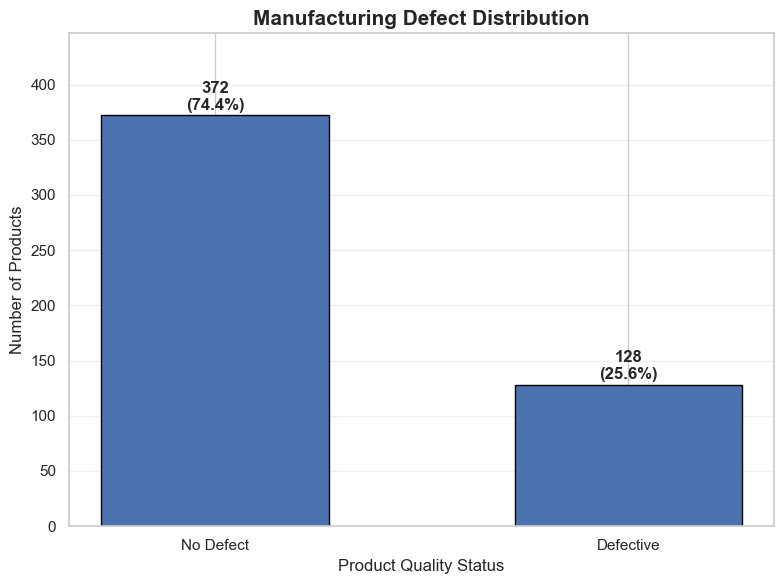


FIGURE 02 SAVED SUCCESSFULLY!
File: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\reports\figures\02_manufacturing_defect_distribution.png
File exists: True

DEFECT DISTRIBUTION:
Defect
No     372
Yes    128
Name: count, dtype: int64

DEFECT PERCENTAGES:
Defect
No     74.4
Yes    25.6
Name: count, dtype: float64

FIGURE 01 EXISTS: True


In [52]:

import matplotlib.pyplot as plt

# Calculate defect counts
defect_counts = raw_df["Defect"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

# Calculate percentages
defect_percentages = (
    defect_counts / len(raw_df) * 100
)

# Create figure
fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(
    ["No Defect", "Defective"],
    defect_counts.values,
    edgecolor="black",
    width=0.55
)

# Add count and percentage labels
for bar, count, percentage in zip(
    bars,
    defect_counts.values,
    defect_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Manufacturing Defect Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Product Quality Status")
ax.set_ylabel("Number of Products")
ax.set_ylim(0, max(defect_counts.values) * 1.2)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save figure
figure_path = (
    figures_dir / "02_manufacturing_defect_distribution.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verify saved figures
print("\nFIGURE 02 SAVED SUCCESSFULLY!")
print("File:", figure_path.resolve())
print("File exists:", figure_path.exists())

print("\nDEFECT DISTRIBUTION:")
print(defect_counts)

print("\nDEFECT PERCENTAGES:")
print(defect_percentages.round(2))

# Verify Figure 01 as well
figure_01 = (
    figures_dir /
    "01_manufacturing_parameter_distributions.png"
)

print("\nFIGURE 01 EXISTS:", figure_01.exists())


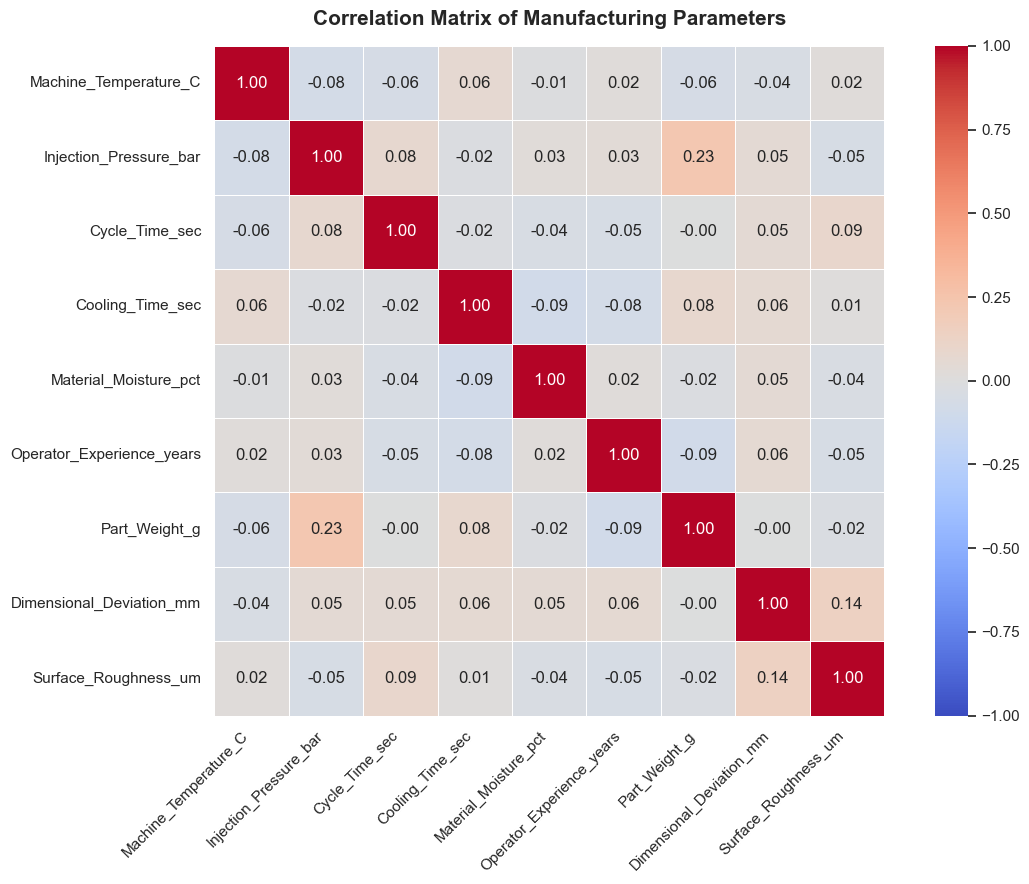


FIGURE 03 SAVED SUCCESSFULLY!
File: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\reports\figures\03_manufacturing_correlation_heatmap.png
File exists: True

CORRELATION MATRIX:
                           Machine_Temperature_C  Injection_Pressure_bar  \
Machine_Temperature_C                      1.000                  -0.076   
Injection_Pressure_bar                    -0.076                   1.000   
Cycle_Time_sec                            -0.058                   0.076   
Cooling_Time_sec                           0.064                  -0.022   
Material_Moisture_pct                     -0.009                   0.026   
Operator_Experience_years                  0.021                   0.032   
Part_Weight_g                             -0.061                   0.230   
Dimensional_Deviation_mm                  -0.041                   0.048   
Surface_Roughness_um                       0.018                  -0.048   

                           Cycl

In [53]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = raw_df.select_dtypes(
    include="number"
).corr()

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Manufacturing Parameters",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save figure
figure_path = (
    figures_dir / "03_manufacturing_correlation_heatmap.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verification
print("\nFIGURE 03 SAVED SUCCESSFULLY!")
print("File:", figure_path.resolve())
print("File exists:", figure_path.exists())

print("\nCORRELATION MATRIX:")
print(correlation_matrix.round(3))


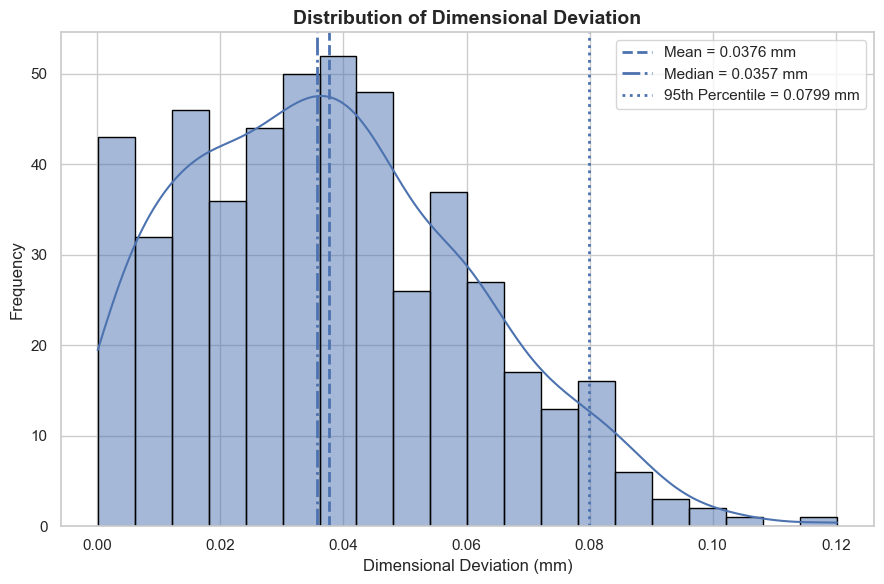

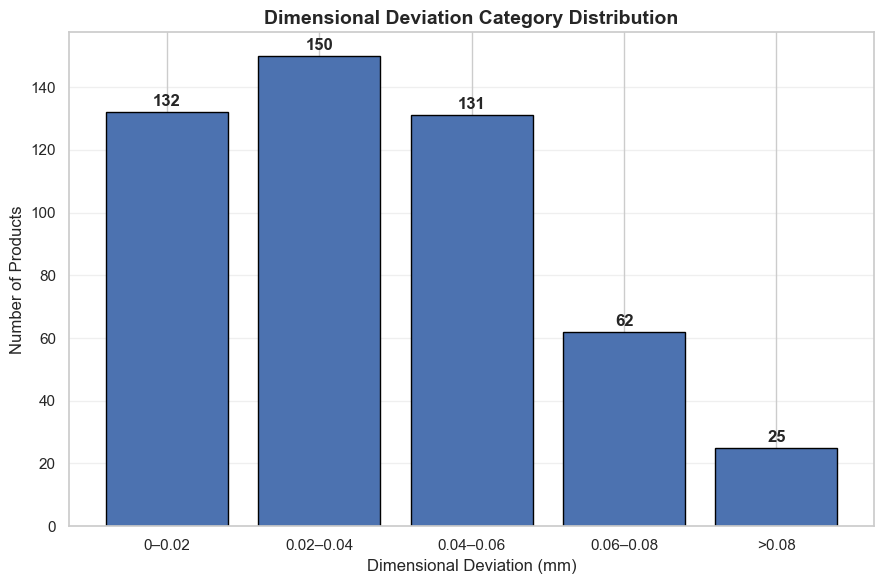

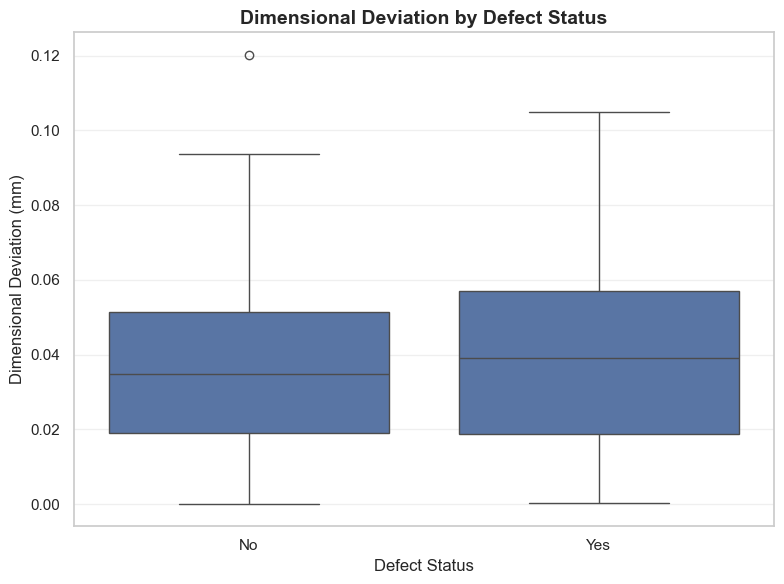


ALL THREE FIGURES GENERATED!
04_dimensional_deviation_distribution.png : True
05_dimensional_deviation_categories.png : True
06_deviation_by_defect_status.png : True

DIMENSIONAL DEVIATION STATISTICS:
count    500.00000
mean       0.03763
std        0.02312
min        0.00009
25%        0.01880
50%        0.03575
75%        0.05378
max        0.12019
Name: Dimensional_Deviation_mm, dtype: float64

CATEGORY COUNTS:
Dimensional_Deviation_mm
0–0.02       132
0.02–0.04    150
0.04–0.06    131
0.06–0.08     62
>0.08         25
Name: count, dtype: int64

AVERAGE DEVIATION BY DEFECT STATUS:
Defect
No     0.03669
Yes    0.04035
Name: Dimensional_Deviation_mm, dtype: float64


In [54]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare dimensional deviation data
deviation = raw_df["Dimensional_Deviation_mm"]

# Create deviation categories
bins = [-np.inf, 0.02, 0.04, 0.06, 0.08, np.inf]

labels = [
    "0–0.02",
    "0.02–0.04",
    "0.04–0.06",
    "0.06–0.08",
    ">0.08"
]

deviation_categories = pd.cut(
    deviation,
    bins=bins,
    labels=labels,
    right=False
)

# ==================================================
# FIGURE 04: Dimensional Deviation Distribution
# ==================================================

fig, ax = plt.subplots(figsize=(9, 6))

sns.histplot(
    deviation,
    bins=20,
    kde=True,
    edgecolor="black",
    ax=ax
)

mean_value = deviation.mean()
median_value = deviation.median()
percentile_95 = deviation.quantile(0.95)

ax.axvline(
    mean_value,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.4f} mm"
)

ax.axvline(
    median_value,
    linestyle="-.",
    linewidth=2,
    label=f"Median = {median_value:.4f} mm"
)

ax.axvline(
    percentile_95,
    linestyle=":",
    linewidth=2,
    label=f"95th Percentile = {percentile_95:.4f} mm"
)

ax.set_title(
    "Distribution of Dimensional Deviation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Dimensional Deviation (mm)")
ax.set_ylabel("Frequency")
ax.legend()

plt.tight_layout()

path_04 = figures_dir / "04_dimensional_deviation_distribution.png"

fig.savefig(path_04, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ==================================================
# FIGURE 05: Dimensional Deviation Categories
# ==================================================

category_counts = deviation_categories.value_counts(
    sort=False
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    labels,
    category_counts.values,
    edgecolor="black"
)

for bar, count in zip(bars, category_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(count),
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Dimensional Deviation Category Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Dimensional Deviation (mm)")
ax.set_ylabel("Number of Products")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

path_05 = figures_dir / "05_dimensional_deviation_categories.png"

fig.savefig(path_05, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ==================================================
# FIGURE 06: Deviation by Defect Status
# ==================================================

plot_df = raw_df[[
    "Defect",
    "Dimensional_Deviation_mm"
]].copy()

fig, ax = plt.subplots(figsize=(8, 6))

sns.boxplot(
    data=plot_df,
    x="Defect",
    y="Dimensional_Deviation_mm",
    order=["No", "Yes"],
    ax=ax
)

ax.set_title(
    "Dimensional Deviation by Defect Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Defect Status")
ax.set_ylabel("Dimensional Deviation (mm)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

path_06 = figures_dir / "06_deviation_by_defect_status.png"

fig.savefig(path_06, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ==================================================
# VERIFICATION AND SUMMARY
# ==================================================

print("\nALL THREE FIGURES GENERATED!")

for path in [path_04, path_05, path_06]:
    print(path.name, ":", path.exists())

print("\nDIMENSIONAL DEVIATION STATISTICS:")
print(deviation.describe().round(5))

print("\nCATEGORY COUNTS:")
print(category_counts)

print("\nAVERAGE DEVIATION BY DEFECT STATUS:")
print(
    raw_df.groupby("Defect")[
        "Dimensional_Deviation_mm"
    ].mean().round(5)
)


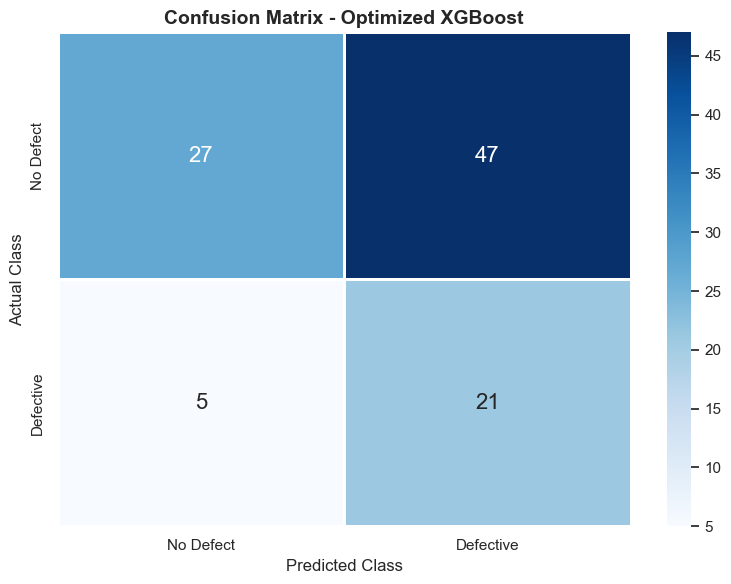


FIGURE 07 SAVED: True

CONFUSION MATRIX:
[[27 47]
 [ 5 21]]

MODEL PERFORMANCE AT THRESHOLD 0.35
Accuracy : 0.48
Precision: 0.3088
Recall   : 0.8077
F1 Score : 0.4468


In [55]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Generate probabilities from optimized XGBoost
xgb_probabilities = best_xgb_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
selected_threshold = 0.35

xgb_predictions = (
    xgb_probabilities >= selected_threshold
).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    xgb_predictions,
    labels=[0, 1]
)

# Create visualization
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=["No Defect", "Defective"],
    yticklabels=["No Defect", "Defective"],
    annot_kws={"size": 16},
    ax=ax
)

ax.set_title(
    "Confusion Matrix - Optimized XGBoost",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

# Save figure
path_07 = (
    figures_dir / "07_optimized_xgboost_confusion_matrix.png"
)

fig.savefig(path_07, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, xgb_predictions)
precision = precision_score(y_test, xgb_predictions, zero_division=0)
recall = recall_score(y_test, xgb_predictions, zero_division=0)
f1 = f1_score(y_test, xgb_predictions, zero_division=0)

print("\nFIGURE 07 SAVED:", path_07.exists())

print("\nCONFUSION MATRIX:")
print(cm)

print("\nMODEL PERFORMANCE AT THRESHOLD 0.35")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))


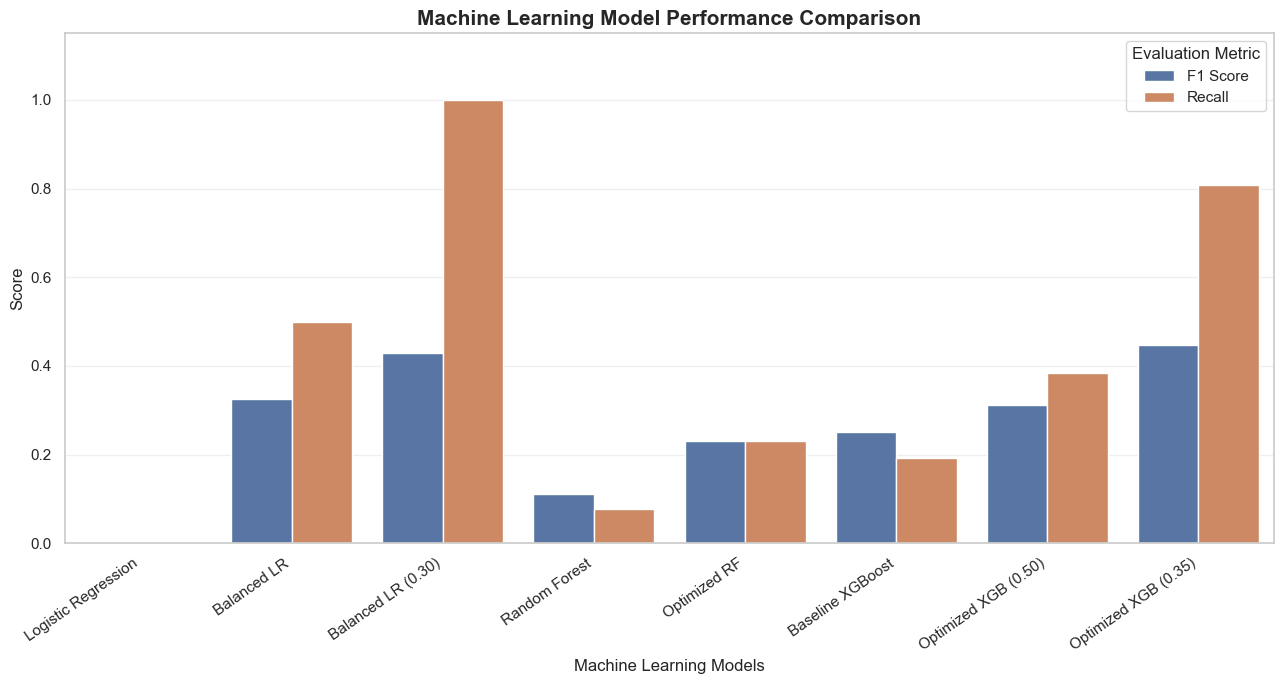

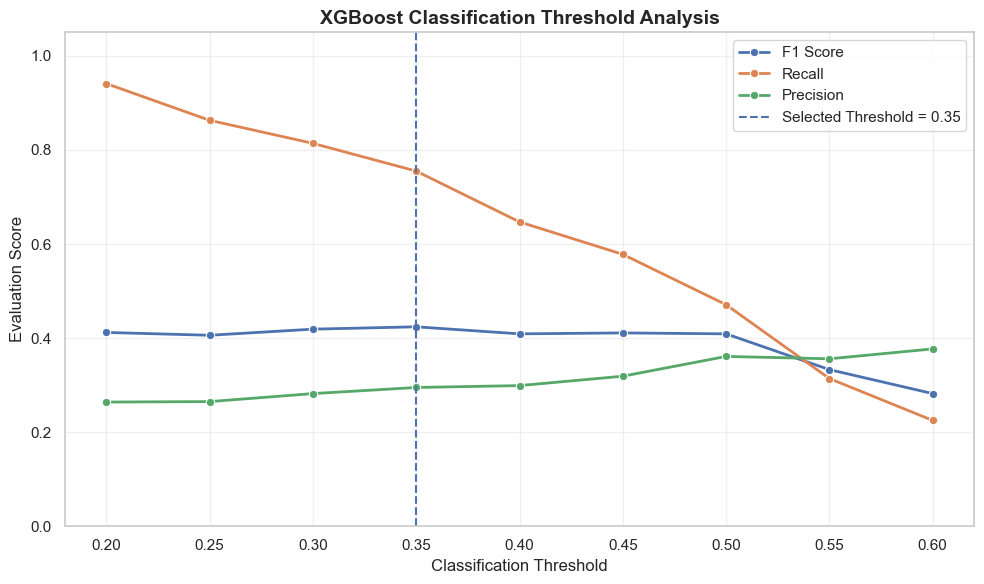

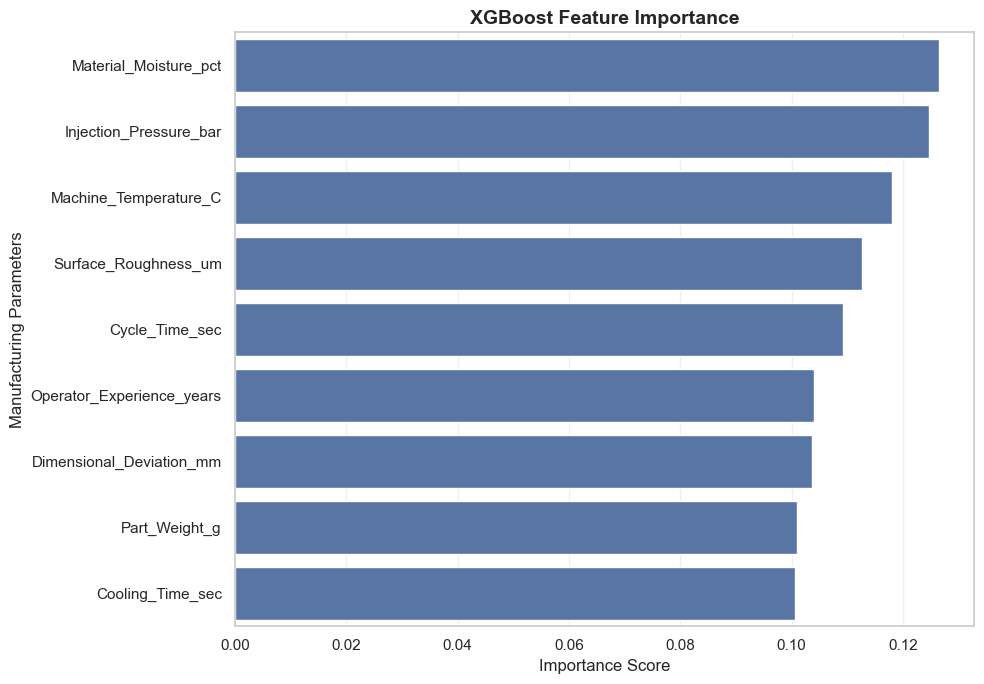

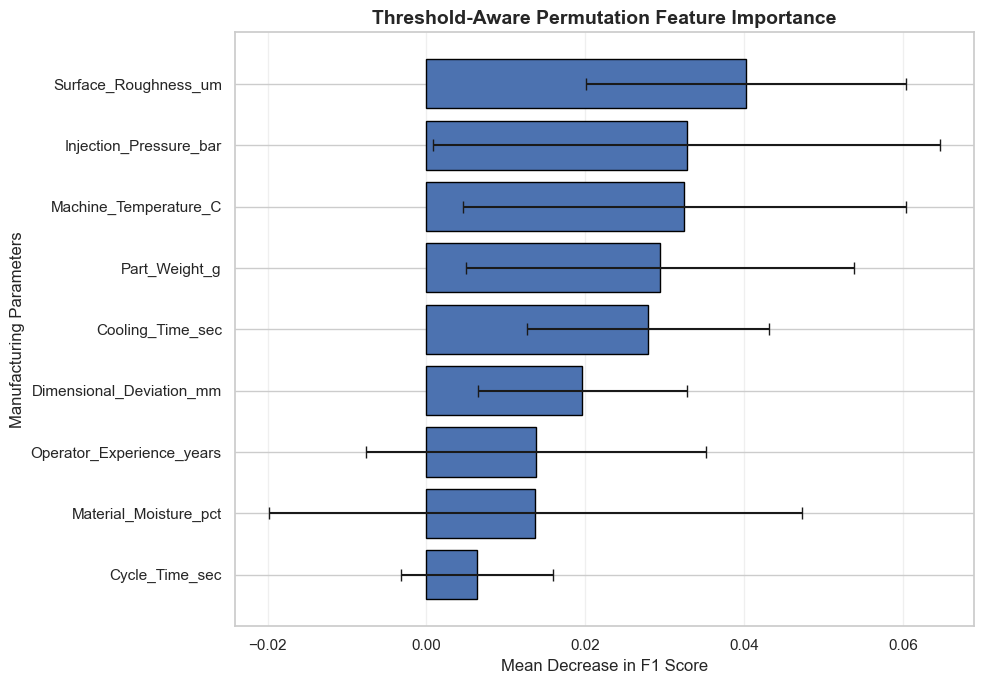


ALL ML FIGURES GENERATED!
08_ml_model_performance_comparison.png : True
09_xgboost_threshold_analysis.png : True
10_xgboost_feature_importance.png : True
11_threshold_aware_permutation_importance.png : True

MODEL COMPARISON:
               Model  F1 Score  Recall
 Logistic Regression    0.0000  0.0000
         Balanced LR    0.3250  0.5000
  Balanced LR (0.30)    0.4298  1.0000
       Random Forest    0.1111  0.0769
        Optimized RF    0.2308  0.2308
    Baseline XGBoost    0.2500  0.1923
Optimized XGB (0.50)    0.3125  0.3846
Optimized XGB (0.35)    0.4468  0.8077

XGBOOST FEATURE IMPORTANCE:
                  Feature  Importance
    Material_Moisture_pct    0.126425
   Injection_Pressure_bar    0.124701
    Machine_Temperature_C    0.117934
     Surface_Roughness_um    0.112607
           Cycle_Time_sec    0.109211
Operator_Experience_years    0.103950
 Dimensional_Deviation_mm    0.103664
            Part_Weight_g    0.100873
         Cooling_Time_sec    0.100636

THRESHOLD-AW

In [56]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==================================================
# FIGURE 08: MODEL PERFORMANCE COMPARISON
# ==================================================

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced LR",
        "Balanced LR (0.30)",
        "Random Forest",
        "Optimized RF",
        "Baseline XGBoost",
        "Optimized XGB (0.50)",
        "Optimized XGB (0.35)"
    ],
    "F1 Score": [
        0.0000, 0.3250, 0.4298, 0.1111,
        0.2308, 0.2500, 0.3125, 0.4468
    ],
    "Recall": [
        0.0000, 0.5000, 1.0000, 0.0769,
        0.2308, 0.1923, 0.3846, 0.8077
    ]
})

plot_data = model_results.melt(
    id_vars="Model",
    value_vars=["F1 Score", "Recall"],
    var_name="Metric",
    value_name="Score"
)

fig, ax = plt.subplots(figsize=(13, 7))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric",
    ax=ax
)

ax.set_title(
    "Machine Learning Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.15)

plt.xticks(rotation=35, ha="right")
ax.legend(title="Evaluation Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

path_08 = figures_dir / "08_ml_model_performance_comparison.png"

fig.savefig(path_08, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 09: CLASSIFICATION THRESHOLD ANALYSIS
# ==================================================

threshold_results = pd.DataFrame({
    "Threshold": [
        0.20, 0.25, 0.30, 0.35, 0.40,
        0.45, 0.50, 0.55, 0.60
    ],
    "F1 Score": [
        0.412, 0.406, 0.419, 0.424, 0.409,
        0.411, 0.409, 0.333, 0.282
    ],
    "Recall": [
        0.941, 0.863, 0.814, 0.755, 0.647,
        0.578, 0.471, 0.314, 0.225
    ],
    "Precision": [
        0.264, 0.265, 0.282, 0.295, 0.299,
        0.319, 0.361, 0.356, 0.377
    ]
})

threshold_plot = threshold_results.melt(
    id_vars="Threshold",
    value_vars=["F1 Score", "Recall", "Precision"],
    var_name="Metric",
    value_name="Score"
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=threshold_plot,
    x="Threshold",
    y="Score",
    hue="Metric",
    marker="o",
    linewidth=2,
    ax=ax
)

ax.axvline(
    0.35,
    linestyle="--",
    linewidth=1.5,
    label="Selected Threshold = 0.35"
)

ax.set_title(
    "XGBoost Classification Threshold Analysis",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Evaluation Score")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

path_09 = figures_dir / "09_xgboost_threshold_analysis.png"

fig.savefig(path_09, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 10: XGBOOST BUILT-IN FEATURE IMPORTANCE
# ==================================================

feature_names = X_train.columns

importance_values = best_xgb_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    ax=ax
)

ax.set_title(
    "XGBoost Feature Importance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Importance Score")
ax.set_ylabel("Manufacturing Parameters")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

path_10 = figures_dir / "10_xgboost_feature_importance.png"

fig.savefig(path_10, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 11: THRESHOLD-AWARE PERMUTATION IMPORTANCE
# ==================================================

permutation_df = pd.DataFrame({
    "Feature": [
        "Surface_Roughness_um",
        "Injection_Pressure_bar",
        "Machine_Temperature_C",
        "Part_Weight_g",
        "Cooling_Time_sec",
        "Dimensional_Deviation_mm",
        "Operator_Experience_years",
        "Material_Moisture_pct",
        "Cycle_Time_sec"
    ],
    "Importance": [
        0.040189, 0.032728, 0.032464,
        0.029386, 0.027928, 0.019600,
        0.013775, 0.013696, 0.006313
    ],
    "Std": [
        0.020111, 0.031955, 0.027919,
        0.024439, 0.015219, 0.013167,
        0.021348, 0.033575, 0.009574
    ]
})

permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    permutation_df["Feature"],
    permutation_df["Importance"],
    xerr=permutation_df["Std"],
    capsize=4,
    edgecolor="black"
)

ax.set_title(
    "Threshold-Aware Permutation Feature Importance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Mean Decrease in F1 Score")
ax.set_ylabel("Manufacturing Parameters")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

path_11 = figures_dir / "11_threshold_aware_permutation_importance.png"

fig.savefig(path_11, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# FINAL VERIFICATION
# ==================================================

print("\nALL ML FIGURES GENERATED!")

for path in [path_08, path_09, path_10, path_11]:
    print(path.name, ":", path.exists())

print("\nMODEL COMPARISON:")
print(model_results.to_string(index=False))

print("\nXGBOOST FEATURE IMPORTANCE:")
print(importance_df.to_string(index=False))

print("\nTHRESHOLD-AWARE PERMUTATION IMPORTANCE:")
print(permutation_df.to_string(index=False))


In [57]:

import joblib
import json
import sys
import importlib.metadata
from pathlib import Path

# Create models directory
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Selected classification threshold
selected_threshold = 0.35

# Prepare model bundle
model_bundle = {
    "model": best_xgb_model,
    "threshold": selected_threshold,
    "feature_names": list(X_train.columns),
    "positive_class": "Yes",
    "negative_class": "No"
}

# Save trained model
model_path = (
    models_dir / "xgboost_defect_prediction_bundle.joblib"
)

joblib.dump(model_bundle, model_path)

# Prepare model metadata
metadata = {
    "project": "Manufacturing Defect Prediction",
    "model": "Optimized XGBoost Classifier",
    "dataset": "Synthetic Manufacturing Dataset",
    "dataset_samples": 500,
    "classification_threshold": selected_threshold,
    "accuracy": 0.48,
    "precision": 0.3088,
    "recall": 0.8077,
    "f1_score": 0.4468,
    "features": list(X_train.columns),
    "target": "Defect",
    "note": (
        "Exploratory results on a synthetic dataset. "
        "Not validated for real industrial deployment."
    )
}

metadata_path = models_dir / "model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

# Verify model by loading it again
loaded_bundle = joblib.load(model_path)

print("MODEL SAVED SUCCESSFULLY!")
print("Model file:", model_path.resolve())
print("Model exists:", model_path.exists())

print("\nMETADATA SAVED SUCCESSFULLY!")
print("Metadata file:", metadata_path.resolve())

print("\nMODEL VERIFICATION:")
print("Loaded model:", type(loaded_bundle["model"]).__name__)
print("Threshold:", loaded_bundle["threshold"])
print("Number of features:", len(loaded_bundle["feature_names"]))

# Verify all 11 figures
print("\nFIGURE VERIFICATION:")

figure_files = sorted(figures_dir.glob("*.png"))

print("Total saved figures:", len(figure_files))

for file in figure_files:
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

# Generate requirements.txt
packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "joblib"
]

requirements_path = project_dir / "requirements.txt"

with open(requirements_path, "w") as file:
    for package in packages:
        version = importlib.metadata.version(package)
        file.write(f"{package}=={version}\n")

print("\nREQUIREMENTS FILE CREATED!")
print(requirements_path.resolve())

print("\nPYTHON VERSION:")
print(sys.version)


MODEL SAVED SUCCESSFULLY!
Model file: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\models\xgboost_defect_prediction_bundle.joblib
Model exists: True

METADATA SAVED SUCCESSFULLY!
Metadata file: D:\AI_ML_Profession\Manufacturing-Defect-Prediction-Using-Machine-Learning\models\model_metadata.json

MODEL VERIFICATION:
Loaded model: XGBClassifier
Threshold: 0.35
Number of features: 9

FIGURE VERIFICATION:
Total saved figures: 11
01_manufacturing_parameter_distributions.png | 782.42 KB
02_manufacturing_defect_distribution.png | 113.73 KB
03_manufacturing_correlation_heatmap.png | 573.87 KB
04_dimensional_deviation_distribution.png | 178.83 KB
05_dimensional_deviation_categories.png | 109.57 KB
06_deviation_by_defect_status.png | 95.88 KB
07_optimized_xgboost_confusion_matrix.png | 109.27 KB
08_ml_model_performance_comparison.png | 256.23 KB
09_xgboost_threshold_analysis.png | 215.63 KB
10_xgboost_feature_importance.png | 179.15 KB
11_threshold_aware_permutation

In [58]:

import joblib
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load saved model bundle
model_path = (
    project_dir /
    "models" /
    "xgboost_defect_prediction_bundle.joblib"
)

loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]
threshold = loaded_bundle["threshold"]
feature_names = loaded_bundle["feature_names"]

# Verify feature compatibility
X_test_verified = X_test[feature_names]

# Generate predictions using loaded model
probabilities = loaded_model.predict_proba(
    X_test_verified
)[:, 1]

predictions = (
    probabilities >= threshold
).astype(int)

# Generate predictions using original model
original_probabilities = best_xgb_model.predict_proba(
    X_test[feature_names]
)[:, 1]

original_predictions = (
    original_probabilities >= threshold
).astype(int)

# Compare original and reloaded model predictions
predictions_match = np.array_equal(
    predictions,
    original_predictions
)

# Evaluate reloaded model
print("SAVED MODEL INFERENCE VERIFICATION")
print("----------------------------------")

print("Threshold:", threshold)
print("Feature count:", len(feature_names))
print("Predictions generated:", len(predictions))

print("\nORIGINAL VS RELOADED MODEL:")
print("Predictions identical:", predictions_match)

print("\nRELOADED MODEL PERFORMANCE:")
print("Accuracy :", round(
    accuracy_score(y_test, predictions), 4
))

print("Precision:", round(
    precision_score(y_test, predictions, zero_division=0), 4
))

print("Recall   :", round(
    recall_score(y_test, predictions, zero_division=0), 4
))

print("F1 Score :", round(
    f1_score(y_test, predictions, zero_division=0), 4
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, predictions))

# Display first 10 predictions
prediction_results = X_test_verified.head(10).copy()

prediction_results["Actual_Defect"] = np.where(
    y_test.loc[prediction_results.index].values == 1,
    "Yes", "No"
)

prediction_results["Predicted_Defect"] = np.where(
    predictions[:10] == 1,
    "Yes", "No"
)

prediction_results["Defect_Probability"] = np.round(
    probabilities[:10], 4
)

print("\nFIRST 10 PREDICTIONS:")
print(prediction_results[[
    "Actual_Defect",
    "Predicted_Defect",
    "Defect_Probability"
]].to_string())

print("\nVERIFICATION COMPLETE!")


SAVED MODEL INFERENCE VERIFICATION
----------------------------------
Threshold: 0.35
Feature count: 9
Predictions generated: 100

ORIGINAL VS RELOADED MODEL:
Predictions identical: True

RELOADED MODEL PERFORMANCE:
Accuracy : 0.48
Precision: 0.3088
Recall   : 0.8077
F1 Score : 0.4468

CONFUSION MATRIX:
[[27 47]
 [ 5 21]]

FIRST 10 PREDICTIONS:
    Actual_Defect Predicted_Defect  Defect_Probability
258            No               No              0.2620
416            No               No              0.3247
120            No              Yes              0.7753
281            No               No              0.2112
1              No               No              0.3384
418            No              Yes              0.4609
67             No              Yes              0.4361
329            No              Yes              0.3886
207           Yes              Yes              0.6273
326           Yes              Yes              0.4874

VERIFICATION COMPLETE!


In [59]:
from pathlib import Path

print("PROJECT FOLDER AUDIT")
print("=" * 60)

for path in sorted(project_dir.rglob("*")):
    if path.is_file():
        relative_path = path.relative_to(project_dir)
        size_kb = path.stat().st_size / 1024

        print(f"{relative_path}  |  {size_kb:.2f} KB")

print("\n" + "=" * 60)

print("IMPORTANT FILE CHECK")

required_files = [
    "data/raw/manufacturing_data_synthetic.csv",
    "models/xgboost_defect_prediction_bundle.joblib",
    "models/model_metadata.json",
    "requirements.txt"
]

for file in required_files:
    file_path = project_dir / file
    print(f"{file}: {'FOUND' if file_path.exists() else 'MISSING'}")

print("\nFIGURE COUNT:",
      len(list(figures_dir.glob("*.png"))))

print("\nNOTEBOOK FILES:")

for file in (project_dir / "notebooks").glob("*.ipynb"):
    print(file.name)

PROJECT FOLDER AUDIT
.gitignore  |  0.36 KB
data\processed\manufacturing_data_with_deviation_category.csv  |  91.30 KB
data\raw\manufacturing_data_synthetic.csv  |  84.37 KB
models\model_metadata.json  |  0.75 KB
models\xgboost_defect_prediction_bundle.joblib  |  178.28 KB
notebooks\.ipynb_checkpoints\manufacturing_defect_prediction-checkpoint.ipynb  |  1916.46 KB
notebooks\manufacturing_data.csv  |  84.37 KB
notebooks\manufacturing_defect_prediction.ipynb  |  661.41 KB
README.md  |  7.51 KB
reports\figures\01_manufacturing_parameter_distributions.png  |  782.42 KB
reports\figures\02_manufacturing_defect_distribution.png  |  113.73 KB
reports\figures\03_manufacturing_correlation_heatmap.png  |  573.87 KB
reports\figures\04_dimensional_deviation_distribution.png  |  178.83 KB
reports\figures\05_dimensional_deviation_categories.png  |  109.57 KB
reports\figures\06_deviation_by_defect_status.png  |  95.88 KB
reports\figures\07_optimized_xgboost_confusion_matrix.png  |  109.27 KB
reports\f

In [60]:
import json

notebook_path = (
    project_dir /
    "notebooks" /
    "manufacturing_defect_prediction.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

print("FINAL DATASET REFERENCE AUDIT")
print("=" * 60)

for i, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        relevant_lines = [
            line.strip()
            for line in source.splitlines()
            if ".read_csv(" in line
            or ".to_csv(" in line
            or "raw_data_path" in line
        ]

        if relevant_lines:
            print(f"\nCell {i}:")

            for line in relevant_lines:
                print(line)

print("\n" + "=" * 60)

print("RAW DATASET FILE CHECK:")

raw_data_path = (
    project_dir /
    "data" /
    "raw" /
    "manufacturing_data_synthetic.csv"
)

print("File Exists:", raw_data_path.exists())

if raw_data_path.exists():
    print("File Size (KB):",
          round(raw_data_path.stat().st_size / 1024, 2))

FINAL DATASET REFERENCE AUDIT

Cell 45:
df.to_csv(processed_dataset_path, index=False)

Cell 47:
raw_df.to_csv(dataset_path, index=False)

Cell 59:
if ".read_csv(" in line
or ".to_csv(" in line
or "raw_data_path" in line
raw_data_path = (
print("File Exists:", raw_data_path.exists())
if raw_data_path.exists():
round(raw_data_path.stat().st_size / 1024, 2))

Cell 61:
raw_check = pd.read_csv(raw_file)
processed_check = pd.read_csv(processed_file)

RAW DATASET FILE CHECK:
File Exists: True
File Size (KB): 84.37


In [61]:
for cell_index in [45, 47]:

    cell = notebook_data["cells"][cell_index]

    print("\n" + "=" * 60)
    print(f"CELL {cell_index} — FULL SOURCE")
    print("=" * 60)

    print("".join(cell["source"]))

print("\n" + "=" * 60)
print("DATASET PATH DEFINITION")
print("=" * 60)

for i, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if "dataset_path" in source:
            print(f"\nCell {i}:")
            print(source)


CELL 45 — FULL SOURCE
# Save processed manufacturing dataset
processed_data_dir = project_dir / "data" / "processed"
processed_data_dir.mkdir(parents=True, exist_ok=True)

processed_dataset_path = (
    processed_data_dir / "manufacturing_data_with_deviation_category.csv"
)

df.to_csv(processed_dataset_path, index=False)

print("PROCESSED DATASET SAVED SUCCESSFULLY!")
print("Dataset Location:", processed_dataset_path.resolve())
print("Dataset Shape:", df.shape)

CELL 47 — FULL SOURCE
# Create a separate copy of the original dataset
raw_df = df.drop(columns=["Deviation_Category"])

# Save the corrected raw dataset
dataset_path = (
    project_dir / "data" / "raw" /
    "manufacturing_data_synthetic.csv"
)

raw_df.to_csv(dataset_path, index=False)

# Verify the saved dataset
print("RAW DATASET SAVED SUCCESSFULLY!")

print("\nRaw Dataset Shape:", raw_df.shape)

print("\nTotal Columns:", len(raw_df.columns))

print("\nColumn Names:")
print(raw_df.columns.tolist())

print("\nDefect Distrib

In [62]:
import pandas as pd

raw_file = (
    project_dir / "data" / "raw" /
    "manufacturing_data_synthetic.csv"
)

processed_file = (
    project_dir / "data" / "processed" /
    "manufacturing_data_with_deviation_category.csv"
)

print("FINAL DATASET VERIFICATION")
print("=" * 55)

print("\nRAW DATASET:")

if raw_file.exists():
    raw_check = pd.read_csv(raw_file)
    print("Exists: YES")
    print("Shape:", raw_check.shape)
    print("Columns:", len(raw_check.columns))
else:
    print("MISSING!")

print("\nPROCESSED DATASET:")

if processed_file.exists():
    processed_check = pd.read_csv(processed_file)
    print("Exists: YES")
    print("Shape:", processed_check.shape)
    print("Columns:", len(processed_check.columns))
else:
    print("MISSING!")

print("\n" + "=" * 55)

FINAL DATASET VERIFICATION

RAW DATASET:
Exists: YES
Shape: (500, 10)
Columns: 10

PROCESSED DATASET:
Exists: YES
Shape: (500, 11)
Columns: 11



In [128]:
from pathlib import Path
import json
import pandas as pd

print("=" * 65)
print("PROJECT 01 — FINAL QUALITY AUDIT")
print("=" * 65)

# 1. Important project files
required_files = {
    "README.md": project_dir / "README.md",
    ".gitignore": project_dir / ".gitignore",
    "requirements.txt": project_dir / "requirements.txt",
    "Jupyter Notebook": project_dir / "notebooks" / "manufacturing_defect_prediction.ipynb",
    "Raw Dataset": raw_data_dir / "manufacturing_data_synthetic.csv",
    "Processed Dataset": processed_data_dir / "manufacturing_data_with_deviation_category.csv",
    "Saved Model": project_dir / "models" / "xgboost_defect_prediction_bundle.joblib",
    "Model Metadata": project_dir / "models" / "model_metadata.json"
}

print("\n1. REQUIRED FILES")
for name, path in required_files.items():
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{name}: {status}")

# 2. Dataset verification
print("\n2. DATASET VERIFICATION")

raw_path = required_files["Raw Dataset"]
processed_path = required_files["Processed Dataset"]

if raw_path.exists():
    raw_check = pd.read_csv(raw_path)
    print("Raw Dataset Shape:", raw_check.shape)
    print("Raw Dataset Columns:", len(raw_check.columns))
    print("Raw Dataset Valid:", raw_check.shape == (500, 10))

if processed_path.exists():
    processed_check = pd.read_csv(processed_path)
    print("Processed Dataset Shape:", processed_check.shape)
    print("Processed Dataset Columns:", len(processed_check.columns))
    print("Processed Dataset Valid:", processed_check.shape == (500, 11))

# 3. Figure verification
print("\n3. FIGURE VERIFICATION")

figures_dir = project_dir / "reports" / "figures"
figure_files = list(figures_dir.glob("*.png"))

print("Total PNG Figures:", len(figure_files))

for figure in sorted(figure_files):
    print("FOUND:", figure.name)

# 4. Git ignore verification
print("\n4. GIT CONFIGURATION")

gitignore_path = project_dir / ".gitignore"

if gitignore_path.exists():
    gitignore_content = gitignore_path.read_text(encoding="utf-8")
    print(
        "Jupyter Checkpoints Ignored:",
        ".ipynb_checkpoints/" in gitignore_content
    )

# 5. Check duplicate dataset in notebook folder
print("\n5. DUPLICATE DATASET CHECK")

duplicate_path = project_dir / "notebooks" / "manufacturing_data.csv"
notebook_path = required_files["Jupyter Notebook"]

if notebook_path.exists():
    with open(notebook_path, "r", encoding="utf-8") as file:
        notebook_data = json.load(file)

    notebook_code = "\n".join(
        "".join(cell.get("source", []))
        for cell in notebook_data.get("cells", [])
        if cell.get("cell_type") == "code"
    )

    duplicate_referenced = "manufacturing_data.csv" in notebook_code

    print("Duplicate CSV Exists:", duplicate_path.exists())
    print("Duplicate CSV Referenced in Notebook:", duplicate_referenced)

print("\n" + "=" * 65)
print("FINAL AUDIT COMPLETED")
print("=" * 65)

PROJECT 01 — FINAL QUALITY AUDIT

1. REQUIRED FILES
README.md: FOUND
.gitignore: FOUND
requirements.txt: FOUND
Jupyter Notebook: FOUND
Raw Dataset: FOUND
Processed Dataset: FOUND
Saved Model: FOUND
Model Metadata: FOUND

2. DATASET VERIFICATION
Raw Dataset Shape: (500, 10)
Raw Dataset Columns: 10
Raw Dataset Valid: True
Processed Dataset Shape: (500, 11)
Processed Dataset Columns: 11
Processed Dataset Valid: True

3. FIGURE VERIFICATION
Total PNG Figures: 11
FOUND: 01_manufacturing_parameter_distributions.png
FOUND: 02_manufacturing_defect_distribution.png
FOUND: 03_manufacturing_correlation_heatmap.png
FOUND: 04_dimensional_deviation_distribution.png
FOUND: 05_dimensional_deviation_categories.png
FOUND: 06_deviation_by_defect_status.png
FOUND: 07_optimized_xgboost_confusion_matrix.png
FOUND: 08_ml_model_performance_comparison.png
FOUND: 09_xgboost_threshold_analysis.png
FOUND: 10_xgboost_feature_importance.png
FOUND: 11_threshold_aware_permutation_importance.png

4. GIT CONFIGURATION


In [130]:
# Remove unnecessary duplicate dataset
duplicate_path = project_dir / "notebooks" / "manufacturing_data.csv"

if duplicate_path.exists():
    duplicate_path.unlink()
    print("Duplicate CSV removed successfully!")
else:
    print("Duplicate CSV does not exist.")

print("Original Raw Dataset Exists:", 
      (raw_data_dir / "manufacturing_data_synthetic.csv").exists())

print("Processed Dataset Exists:", 
      (processed_data_dir / "manufacturing_data_with_deviation_category.csv").exists())

Duplicate CSV removed successfully!
Original Raw Dataset Exists: True
Processed Dataset Exists: True
